# [Zenodo:8009633](https://www.ebi.ac.uk/biostudies/arrayexpress/studies/E-MTAB-6798)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-03-16
> - Modified: 2025-03-16

# 1. Experimental Design

> Bulk RNA-seq dataset of human embryonic stem cells (hESCs) differentiation. The dataset consists of 31 bulk samples obtained from human embryonic stem cells undergoing undirected differentiation. The samples were collected at 16 time points on days 0 and 7-21 of differentiation. The file contains the raw read counts.
> - Biran, H., Hashimshony, T., Lahav, T. et al. Detecting significant expression patterns in single-cell and spatial transcriptomics with a flexible computational approach. Sci Rep 14, 26121 (2024). https://doi.org/10.1038/s41598-024-75314-3.
> - CEL-seq2
> - Illumina Nextseq 550, PE25+60
> - GRCh38

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/dataset_expression/Zenodo"

In [3]:
raw_counts <- data_dir |>
    file.path("zenodo_8009633_human_differentiation_count_matrix.csv") |>
    read.table(row.names = 1, header = TRUE, sep = "\t") |>
    as.matrix()

dim(raw_counts)

[1] 32863    31

In [4]:
time_levels <- paste0("X", c(0, seq(7, 21, 1)))

In [5]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    separate(
        col = sample, into = c("Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Time = factor(Time, levels = time_levels),
        Replicate = factor(Replicate)) |> 
    arrange(Time, Replicate, sample) |> 
    column_to_rownames("sample")

head(coldata)

table(coldata$Replicate, coldata$Time)

,Time,Replicate
,<fct>,<fct>
X0_D2,X0,D2
X0_D3,X0,D3
X7_D2,X7,D2
X7_D3,X7,D3
X8_D2,X8,D2
X8_D3,X8,D3


    
     X0 X7 X8 X9 X10 X11 X12 X13 X14 X15 X16 X17 X18 X19 X20 X21
  D2  1  1  1  1   1   1   1   1   1   1   1   1   1   1   0   1
  D3  1  1  1  1   1   1   1   1   1   1   1   1   1   1   1   1

In [6]:
anno_gene <- file.path("~/reference/Homo_sapiens/hg38", "gencode.v48.annotation.rds") |>
    readRDS()
anno_gene

GRanges object with 54978 ranges and 3 metadata columns:
                  seqnames      ranges strand |          symbol           type
                     <Rle>   <IRanges>  <Rle> |     <character>    <character>
  ENSG00000290825     chr1 11121-24894      + |        DDX11L16         lncRNA
  ENSG00000310526     chr1 14356-30744      - |          WASH7P         lncRNA
  ENSG00000243485     chr1 28589-31109      + |     MIR1302-2HG         lncRNA
  ENSG00000237613     chr1 34553-37595      - |         FAM138A         lncRNA
  ENSG00000308361     chr1 36526-40778      + | ENSG00000308361         lncRNA
              ...      ...         ...    ... .             ...            ...
  ENSG00000212907     chrM 10470-10766      + |         MT-ND4L protein_coding
  ENSG00000198886     chrM 10760-12137      + |          MT-ND4 protein_coding
  ENSG00000198786     chrM 12337-14148      + |          MT-ND5 protein_coding
  ENSG00000198695     chrM 14149-14673      - |          MT-ND6 protein_co

## 2). Object Construction

In [7]:
common_genes <- intersect(rownames(raw_counts), names(anno_gene))

In [8]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts[common_genes, rownames(coldata)]), 
    rowRanges = anno_gene[common_genes], colData = coldata)

eSet

class: RangedSummarizedExperiment 
dim: 24909 31 
metadata(0):
assays(1): counts
rownames(24909): ENSG00000000003 ENSG00000000005 ... ENSG00000285991
  ENSG00000285992
rowData names(3): symbol type basepairs
colnames(31): X0_D2 X0_D3 ... X21_D2 X21_D3
colData names(2): Time Replicate

In [9]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts[common_genes, rownames(coldata)],
    rowData = anno_gene[common_genes], colData = coldata, 
    design = ~ Time)

dds

class: DESeqDataSet 
dim: 24909 31 
metadata(1): version
assays(1): counts
rownames(24909): ENSG00000000003 ENSG00000000005 ... ENSG00000285991
  ENSG00000285992
rowData names(3): symbol type basepairs
colnames(31): X0_D2 X0_D3 ... X21_D2 X21_D3
colData names(2): Time Replicate

In [10]:
dgel <- DGEList(
    counts = raw_counts[common_genes, rownames(coldata)],
    genes = anno_gene[common_genes], 
    samples = coldata, group = coldata$Time)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [11]:
keep <- rowSums(assay(eSet) >= 10) >= 2
# keep <- rowSums(counts(dds) >= 10) >= 2

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 13394 
 Remove: 11515 
 Retention rate: 53.77 %


In [12]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 14114 
 Remove: 10795 
 Retention rate: 56.66 %


# 3. Normalization

In [13]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [14]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [15]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [16]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [17]:
vsd <- vst(dds, blind = FALSE)

In [18]:
suppressPackageStartupMessages(library(vsn))

In [19]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [20]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


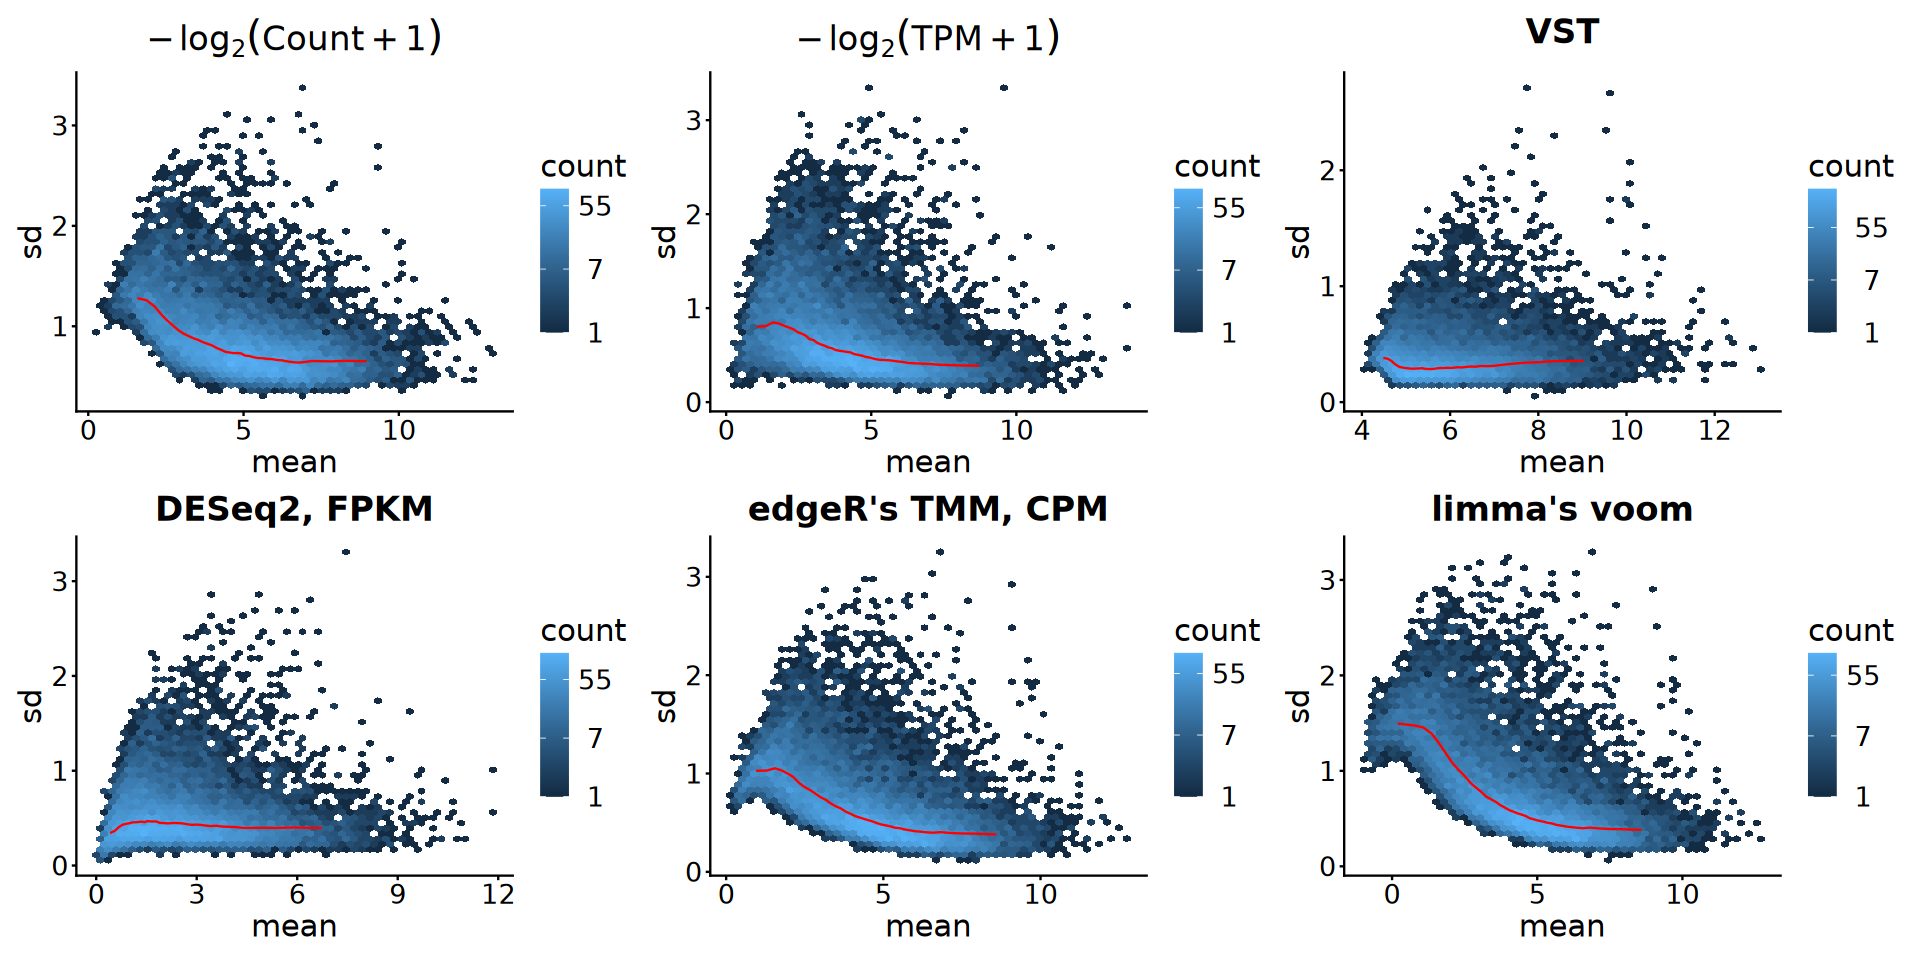

In [21]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [22]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(vsd)

### 1). Overview

In [23]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Time, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

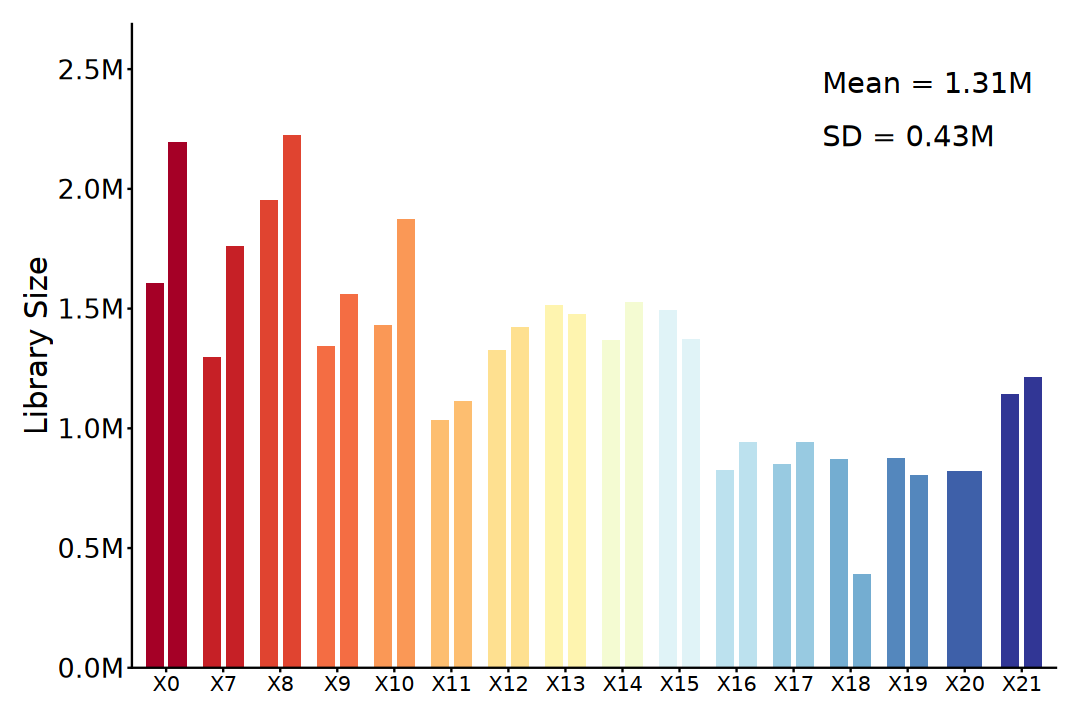

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Time, y = librarySize)) +
    geom_col(
        aes(fill = Time, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = FALSE) +
    annotate(
        geom = "text", x = 12.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 12.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 12),
        axis.text.y = element_text(size = 16))

## 2). PCA

In [25]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [26]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [27]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [28]:
pca_res <- plotPCA(
    vsd, intgroup = c("Time", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [29]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [30]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [31]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Time, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

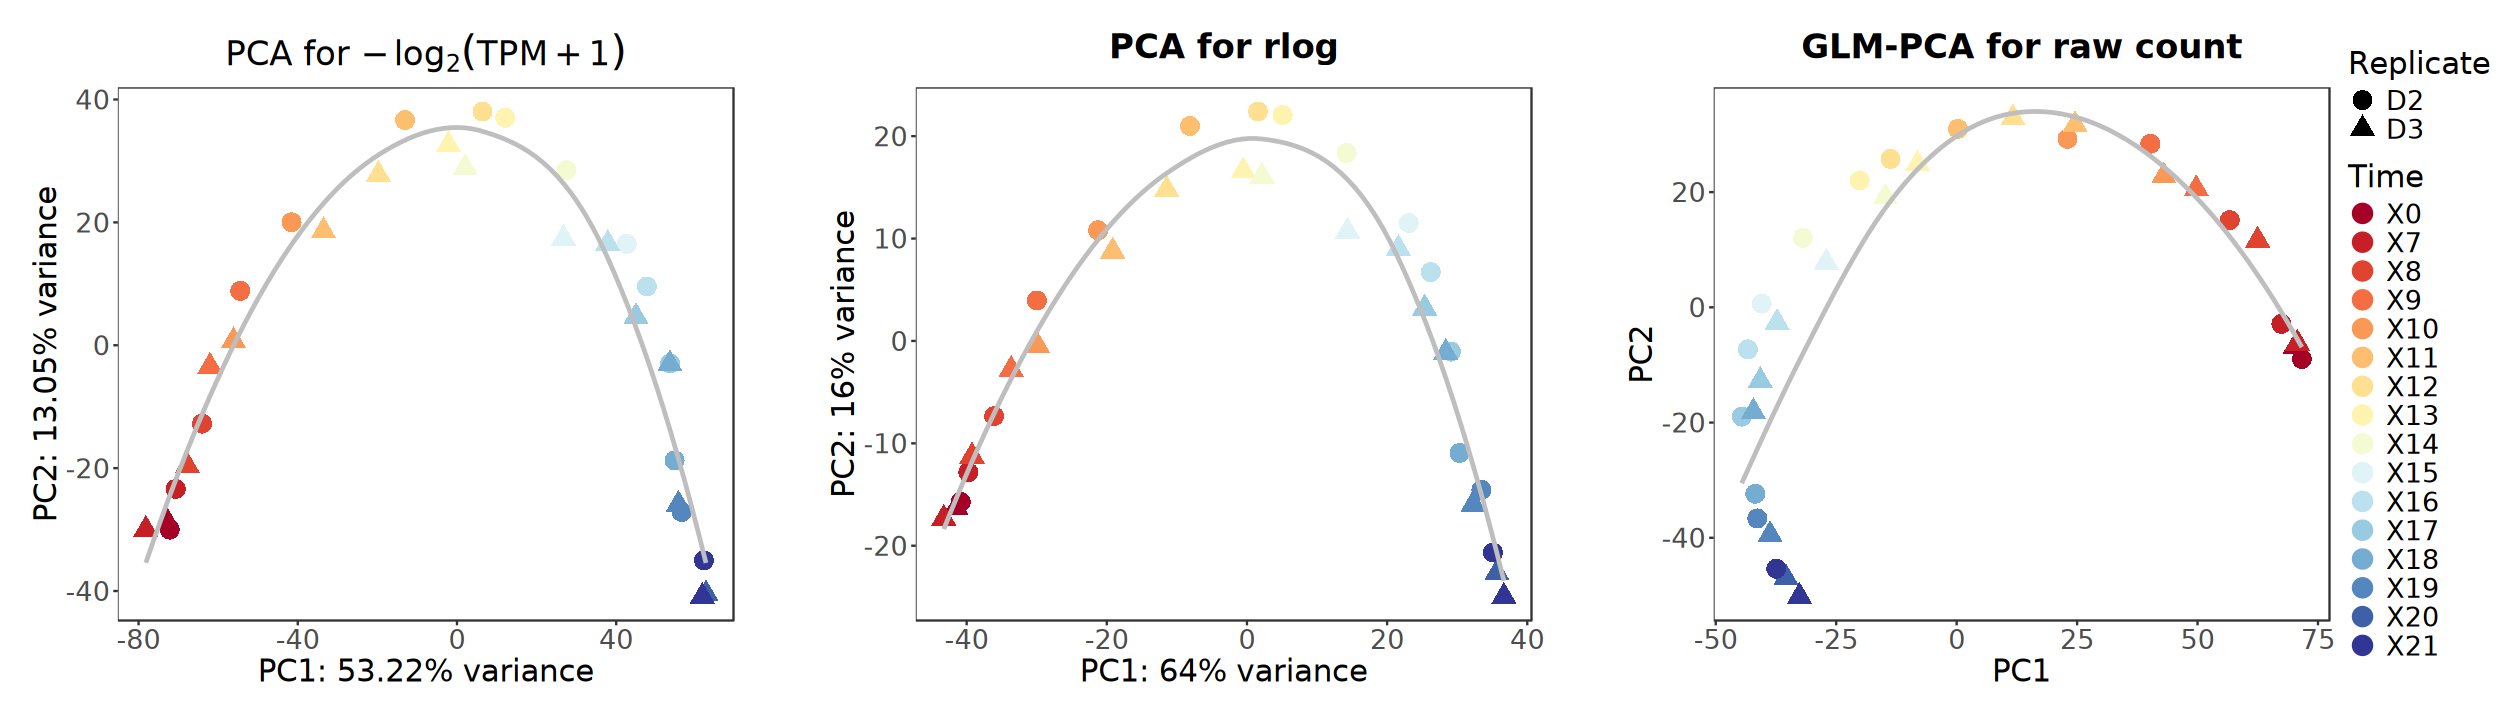

In [32]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [33]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

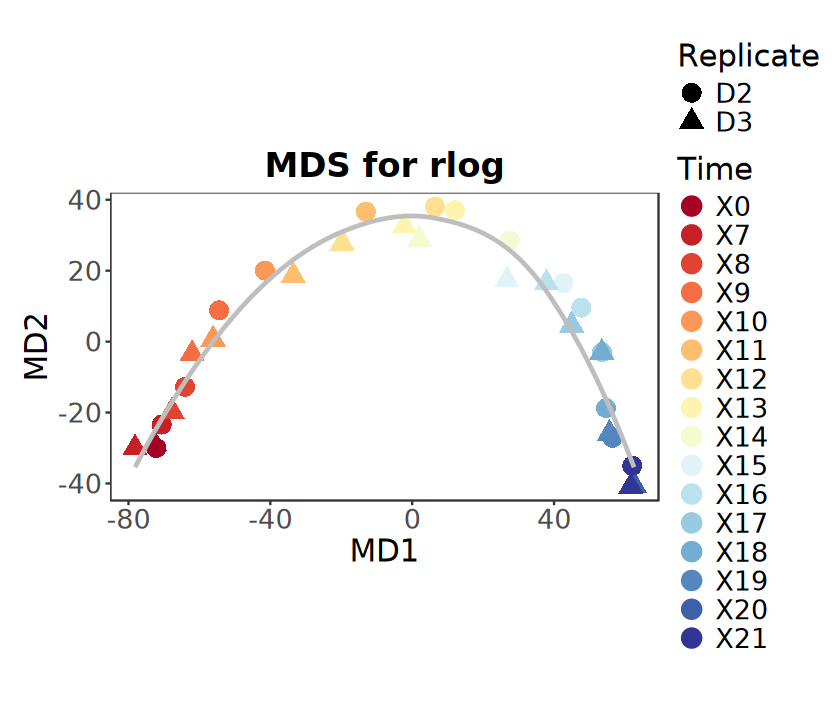

In [34]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Time, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    # geom_path(
    #     aes(group = 1), color = "black", 
    #     arrow = arrow(length = unit(0.15, "inches"))) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [35]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

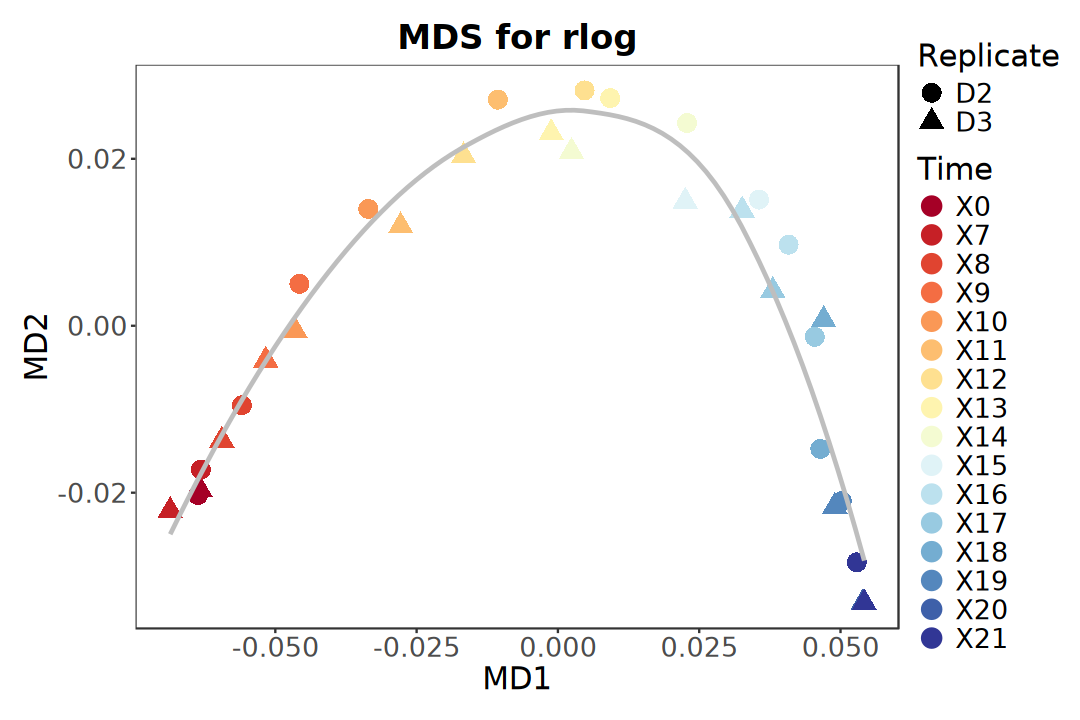

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Time, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [37]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Time)

In [38]:
group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Time = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [39]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

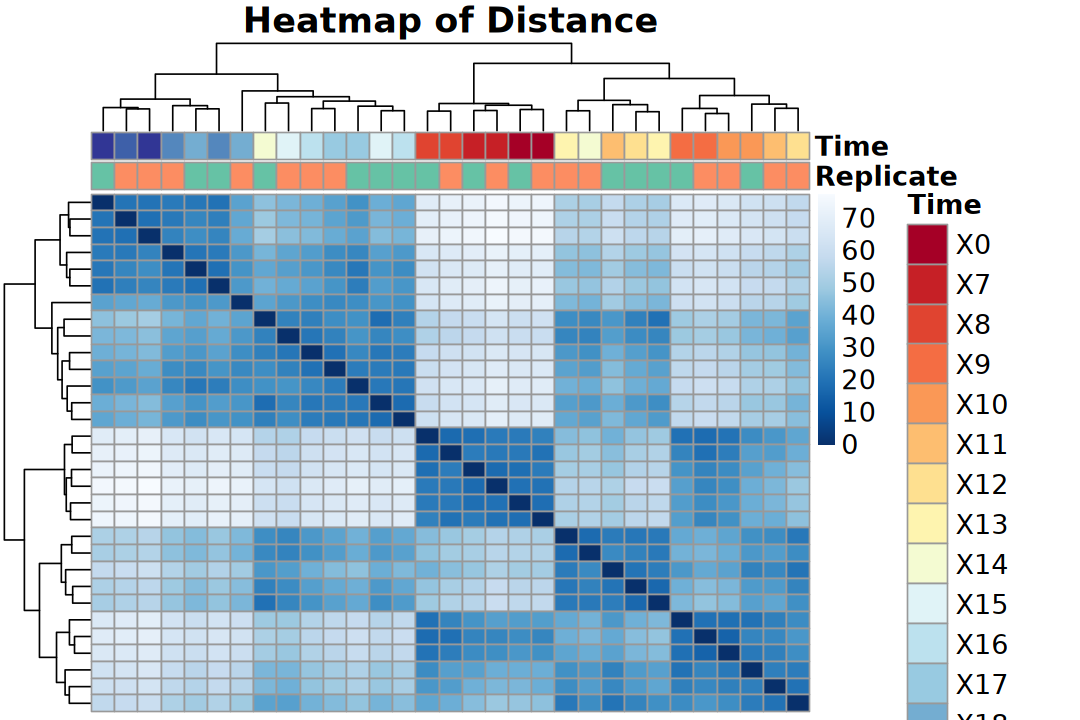

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [41]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

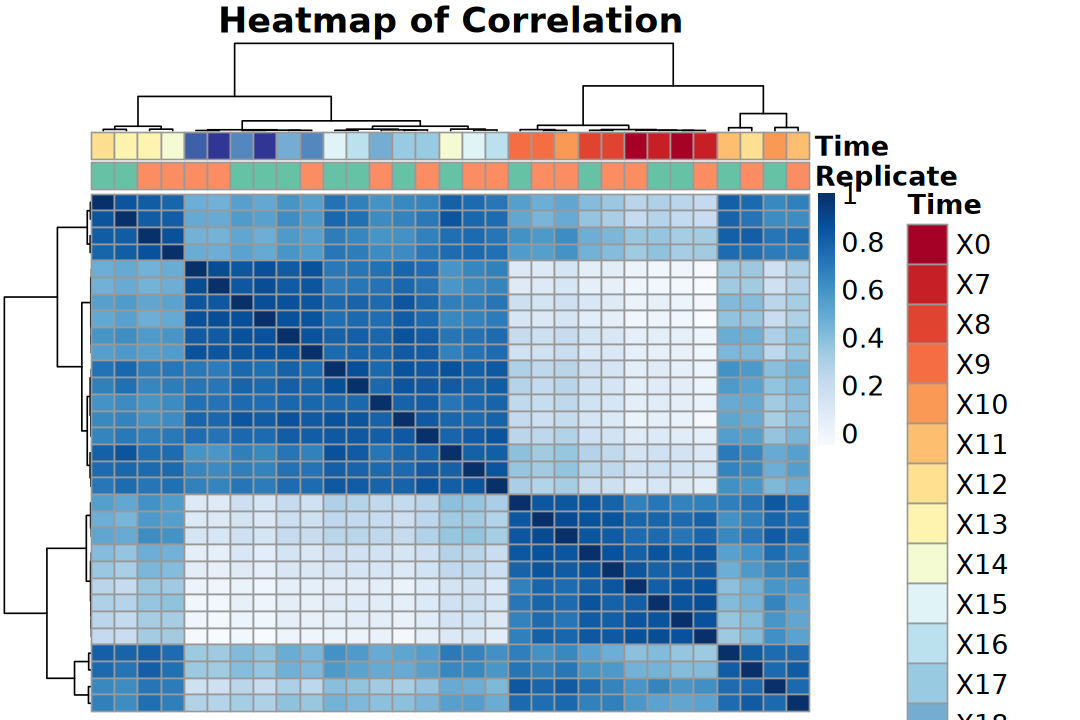

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

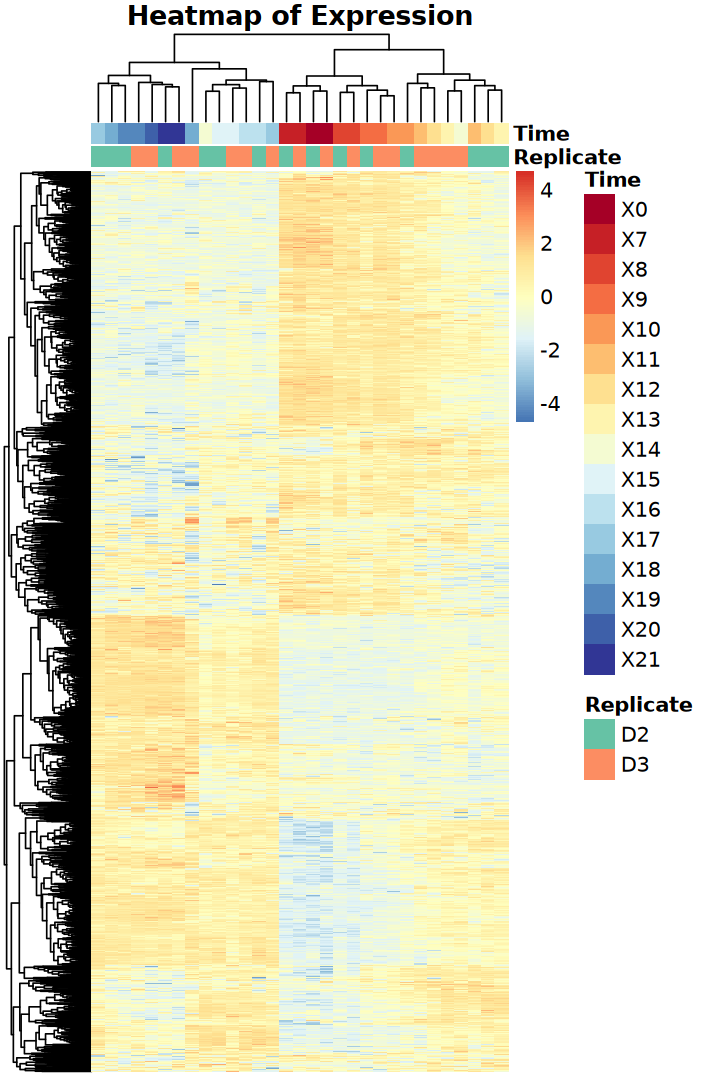

In [43]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

In [44]:
p1 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE, 
    silent = TRUE)

In [45]:
p2 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE, 
    cluster_cols = FALSE, silent = TRUE)

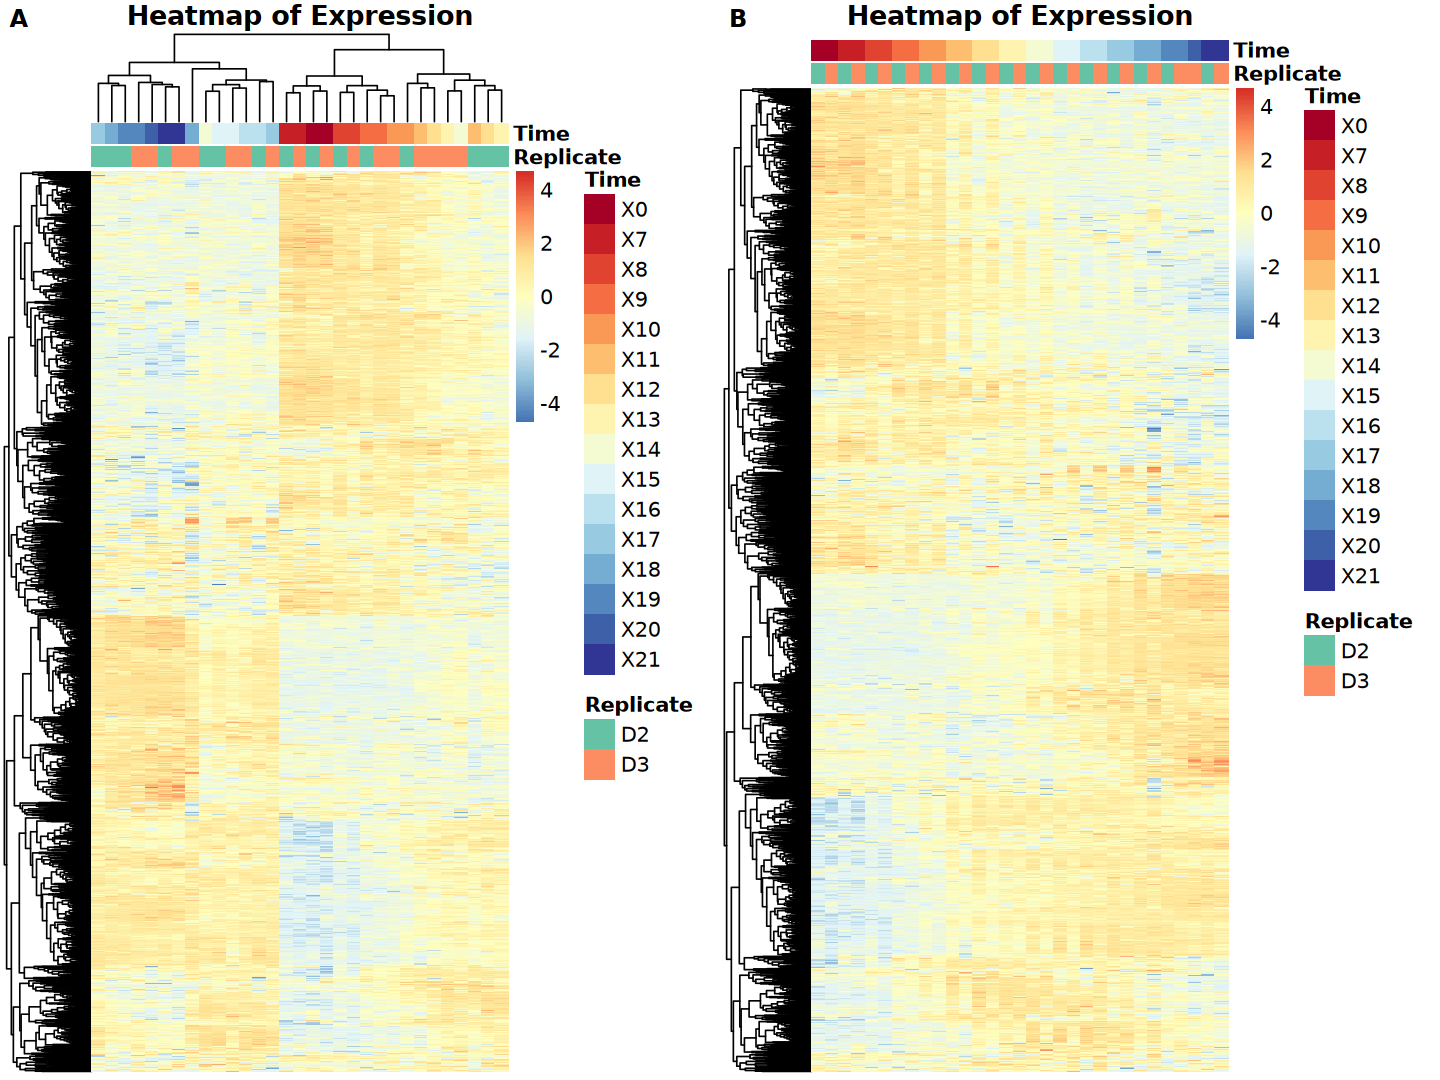

In [46]:
options(repr.plot.width = 12, repr.plot.height = 9)
cowplot::plot_grid(p1[[4]], p2[[4]], labels = c("A", "B"), ncol = 2)

# 5. DEGs: Pairwise

> Sequential pairwise contrast is a differential expression analysis strategy that compares consecutive time points or developmental stages to identify stage-specific transcriptional dynamics. The primary advantage of this localized approach lies in its ability to capture temporal gene expression trajectories and pinpoint critical transition windows with high chronological resolution. However, this sequential strategy inevitably escalates the multiple-testing burden and may overlook cumulative expression changes spanning distant stages. Consequently, it is frequently complemented by global or longitudinal analytical frameworks to achieve a holistic view of the transcriptomic landscape.

# 6. Time-course Dynamics

## 1). DEGs: Dynamic Gene Selection

### a). DESeq2 (LRT)

> The likelihood ratio test (LRT) is useful for testing multiple terms at once, for example testing 3 or more levels of a factor at once, or all interactions between two variables. The LRT for count data is conceptually similar to an analysis of variance (ANOVA) calculation in linear regression, except that in the case of the Negative Binomial GLM, we use an analysis of deviance (ANODEV), where the deviance captures the difference in likelihood between a full and a reduced model.
> - Identifies genes with significant expression dynamics across conditions. By comparing the full factors model against a reduced model, LRT filters out invariant baseline features and captures any temporal patterns  (e.g., monotonic or wave-like), serving as a crucial input for clustering.

In [47]:
design(dds)

~Time

In [48]:
dds <- DESeq(dds, test = "LRT", reduced = ~ 1)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [49]:
deseq2_lrt_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |> 
            factor(levels = c("Sig", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_result$result)


  Sig    NS 
 3014 10380 

### b). edgeR (ANOVA-like)

> ANOVA-like test for any differences. In edgeR, this is done by specifying multiple coefficients to glmQLFTest or glmLRT, when the design matrix includes an intercept term.

In [50]:
design <- model.matrix(~ group, data = dgel$samples)

In [51]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlft <- glmQLFTest(fit, coef = 2:ncol(design))

In [52]:
edgeR_anova_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |>
            factor(levels = c("Sig", "NS")))

table(edgeR_anova_result$result)


  Sig    NS 
 1358 12756 

In [53]:
comparison_df <- deseq2_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_deseq2 = result) |> 
    inner_join(
        edgeR_anova_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
cat("Contrast:", "Stages", "\n")
cat("=========================================\n")
print(table(
    DESeq2 = comparison_df$result_deseq2, 
    edgeR = comparison_df$result_edger))


Contrast: Stages 
      edgeR
DESeq2   Sig    NS
   Sig  1356  1658
   NS      2 10296


## 2). Trend Clustering

> It is recommended to use genes with significant differential expression to enhance computational efficiency. Of course, all genes can also be selected for cluster analysis.

In [54]:
sig_gene_ids <- deseq2_lrt_result |> 
    dplyr::filter(result == "Sig") |> rownames()

message(
    "Number of time-significantly dynamic genes identified by LRT:", 
    length(sig_gene_ids), "\n")

Number of time-significantly dynamic genes identified by LRT:3014




In [55]:
norm_tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
norm_ltpm <- log2(norm_tpm + 1)
norm_mat <- norm_ltpm[sig_gene_ids, ]

# rld_mat <- assay(rlog(dds, blind = FALSE))
# vst_mat <- assay(vst(dds, blind = FALSE))
# norm_mat <- vst_mat[sig_gene_ids, ]

In [56]:
times <- eSet$Time

norm_mean_mat <- sapply(time_levels, function(time) {
    rowMeans(norm_mat[, times == time, drop = FALSE])
})

print(dim(norm_mean_mat))
print(head(norm_mean_mat))

[1] 3014   16


                      X0       X7       X8       X9      X10      X11      X12
ENSG00000000003 7.550106 7.865724 8.037013 8.145793 8.118649 8.139422 8.458174
ENSG00000001617 4.778619 4.999214 4.420622 4.619391 5.380218 4.701455 5.003026
ENSG00000002933 2.773009 2.844314 3.113795 3.935023 3.734622 4.360987 4.917617
ENSG00000003096 2.681193 3.666281 2.381300 2.705273 2.088667 2.204297 2.566136
ENSG00000003137 1.812606 1.177711 1.097022 2.350867 2.551382 3.193138 4.065397
ENSG00000003147 4.800473 4.923235 4.492726 4.219744 4.023441 4.391704 4.298382
                     X13      X14      X15      X16       X17      X18
ENSG00000000003 8.286988 8.178721 7.659407 7.724888 7.7278151 7.174555
ENSG00000001617 4.874583 4.757338 4.605474 3.857076 4.1616944 3.616591
ENSG00000002933 5.071201 6.217753 6.857769 6.834686 6.3393837 7.716271
ENSG00000003096 2.389625 2.274404 1.697333 1.398522 0.6122433 1.349627
ENSG00000003137 4.192566 4.898350 5.360776 4.600641 4.2528594 4.226383
ENSG00000003147 4.229

### a). Mfuzz

> Soft clustering: fuzzy c-means algorithm (of the e1071 package) based on minimization of a weighted square error function.

In [57]:
suppressPackageStartupMessages(library(Mfuzz))

Warning message:
“no DISPLAY variable so Tk is not available”


In [58]:
# Filtering of genes based on their standard deviation
cl_eset <- ExpressionSet(assayData = norm_mean_mat) |>
    filter.std(min.std = 0.5, visu = FALSE) |>
    standardise()
cl_eset

408 genes excluded.


ExpressionSet (storageMode: lockedEnvironment)
assayData: 2606 features, 16 samples 
  element names: exprs 
protocolData: none
phenoData: none
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [59]:
# Estimate for optimal fuzzifier m
m_val <- mestimate(cl_eset)
message(paste0("fuzzifier m: ", m_val))

set.seed(123)
cl_mfuzz <- mfuzz(cl_eset, c = 6, m = m_val)
cl_mfuzz$cluster |> table()

fuzzifier m: 1.16288729365964




  1   2   3   4   5   6 
370 520 173 691 440 412 

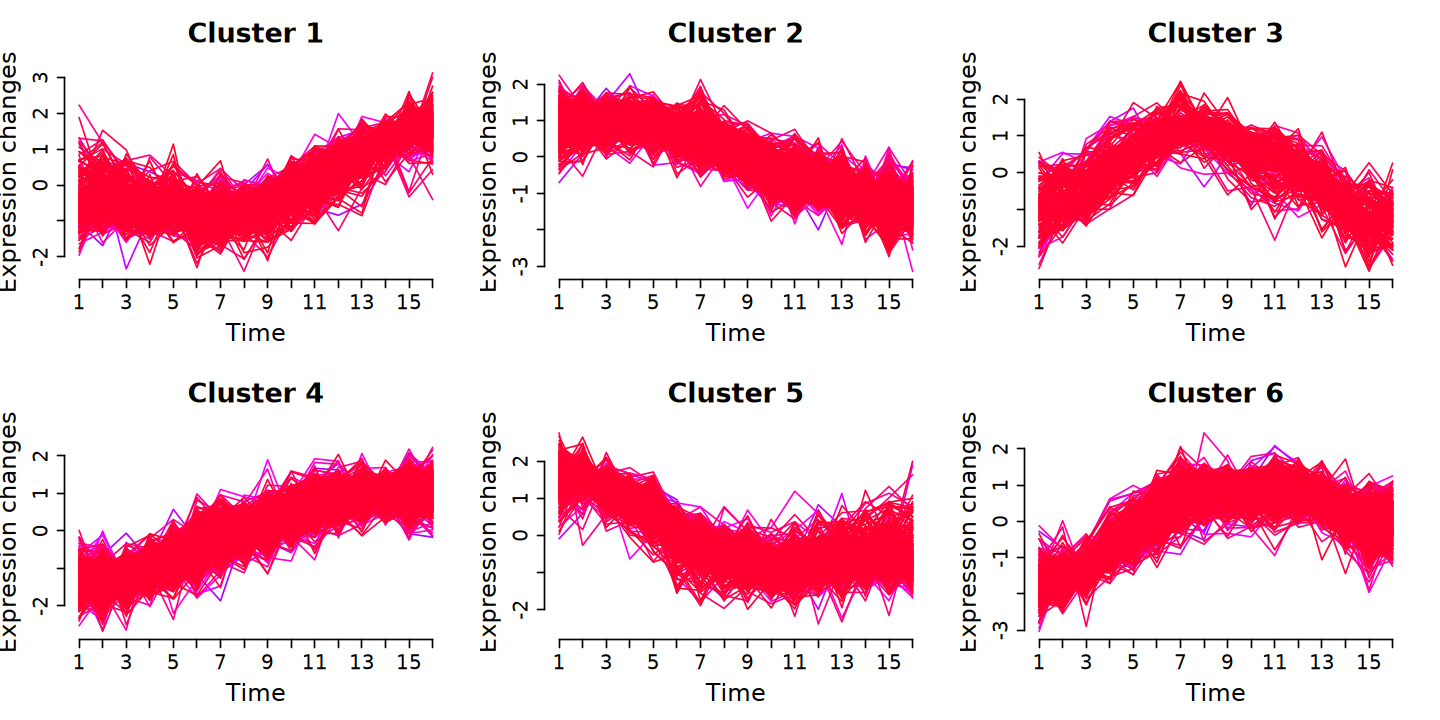

In [60]:
options(repr.plot.width = 12, repr.plot.height = 6)

mfuzz.plot2(
    cl_eset, cl = cl_mfuzz, mfrow = c(2, 3), 
    min.mem = 0.8, x11 = FALSE, cex.main = 2,
    cex.lab = 1.8, cex.axis = 1.5)

### b). TCseq

In [61]:
suppressPackageStartupMessages(library(TCseq))

Warning message:
“replacing previous import ‘e1071::element’ by ‘ggplot2::element’ when loading ‘TCseq’”


In [62]:
norm_mean_filtered_tpm <- norm_mean_mat[rowSds(norm_mean_mat) >= 0.5, ]

set.seed(123)
cl_tcseq <- timeclust(
    norm_mean_filtered_tpm, algo = "cm", k = 6, standardize = TRUE)
cl_tcseq@cluster |> table()


  1   2   3   4   5   6 
442 485 291 436 503 449 

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the TCseq package.
  Please report the issue to the authors.”


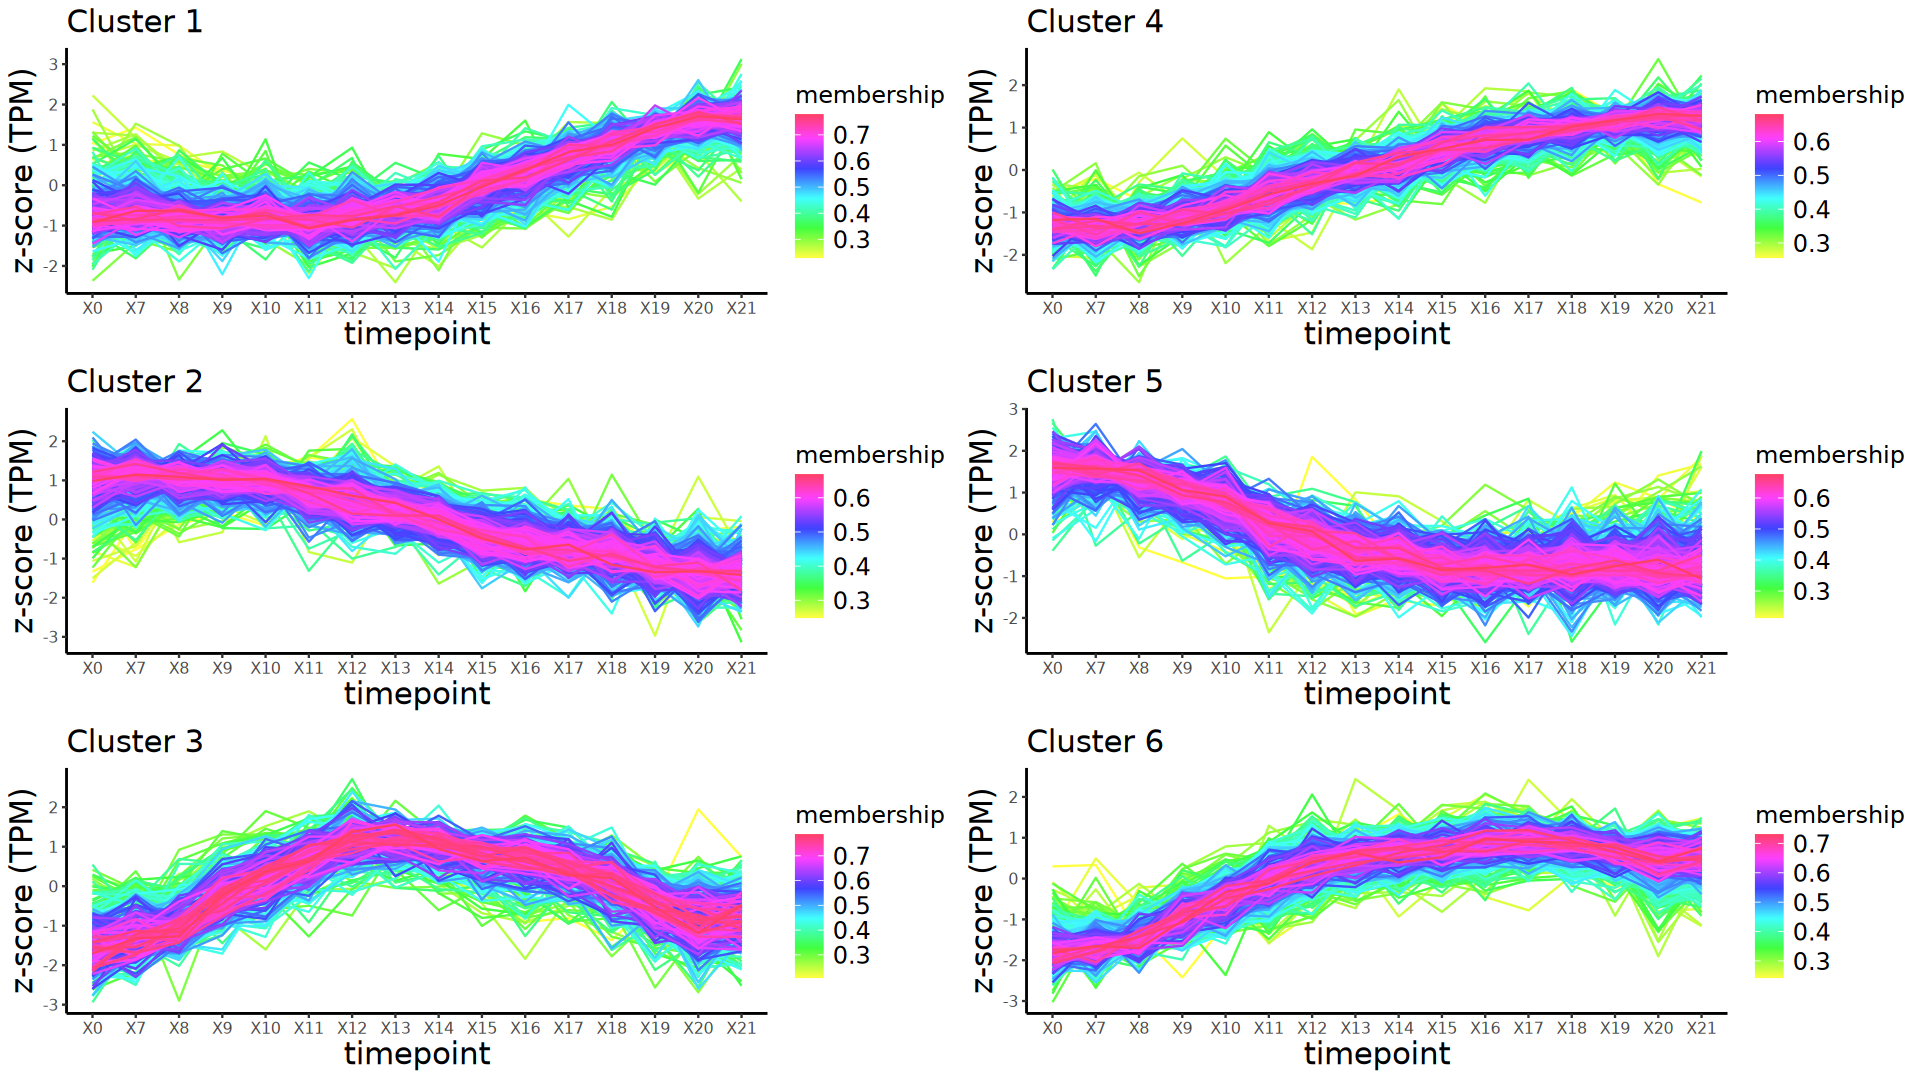

In [63]:
options(repr.plot.width = 16, repr.plot.height = 9)

p <- timeclustplot(
    cl_tcseq, value = "z-score (TPM)", cols = 2, axis.text.size = 9)

### [TiSA](https://github.com/Ylefol/TimeSeriesAnalysis)?

PART clustering

- Yohan Lefol, Tom Korfage, Robin Mjelle, Christian Prebensen, Torben Lüders, Bruno Müller, Hans Krokan, Antonio Sarno, Lene Alsøe, CONSORTIUM LEMONAID, Jan-Erik Berdal, Pål Sætrom, Hilde Nilsen, Diana Domanska, TiSA: TimeSeriesAnalysis—a pipeline for the analysis of longitudinal transcriptomics data, NAR Genomics and Bioinformatics, Volume 5, Issue 1, March 2023, lqad020, https://doi.org/10.1093/nargab/lqad020.

## 3). Regression

### a). maSigPro

> maSigPro follows a two-step regression strategy to find genes with significant temporal expression changes and significant differences between experimental groups.

In [64]:
suppressPackageStartupMessages(library(maSigPro))

In [65]:
design_df <- colData(eSet) |> as.data.frame() |> 
    mutate(
        Time = as.integer(Time), 
        Replicate = as.integer(Replicate), 
        Group = 1) |> 
    dplyr::select(Time, Replicate, Group) |>
    arrange(Time, Replicate)

head(design_df)

,Time,Replicate,Group
,<int>,<int>,<dbl>
X0_D2,1,1,1
X0_D3,1,2,1
X7_D2,2,1,1
X7_D3,2,2,1
X8_D2,3,1,1
X8_D3,3,2,1


In [66]:
# Defining the regression model
# degree = time points - 1
# Usually, a polynomial of degree 2 is more than enough to model the gene expression, 
# although a degree 3 may be appropriate in experacimental setups with a big number of
# time points.
design <- make.design.matrix(design_df, degree = 3)

In [67]:
# dgel <- estimateGLMCommonDisp(dgel, design = design)
# phi <- dgel$common.dispersion
# theta <- 1/phi
1 / dgel$common.dispersion

[1] 16.14525

In [68]:
# DEseq2
# norm_counts <- counts(dds, normalized = TRUE)

# # edgeR
# eff_lib_size <- dgel$samples$lib.size * dgel$samples$norm.factors
# norm_counts <- t(t(dgel$counts) / eff_lib_size) * mean(eff_lib_size)

# TPM
norm_counts <- norm_ltpm

In [69]:
# Performs regression analysis for each gene to identify significant ones.
fit <- p.vector(
    norm_counts, design, counts = TRUE, 
    theta = 16, Q = 0.05, MT.adjust = "BH")

[1] "fitting  gene 100 out of 13394"
[1] "fitting  gene 200 out of 13394"
[1] "fitting  gene 300 out of 13394"
[1] "fitting  gene 400 out of 13394"
[1] "fitting  gene 500 out of 13394"
[1] "fitting  gene 600 out of 13394"
[1] "fitting  gene 700 out of 13394"
[1] "fitting  gene 800 out of 13394"
[1] "fitting  gene 900 out of 13394"
[1] "fitting  gene 1000 out of 13394"
[1] "fitting  gene 1100 out of 13394"
[1] "fitting  gene 1200 out of 13394"
[1] "fitting  gene 1300 out of 13394"
[1] "fitting  gene 1400 out of 13394"
[1] "fitting  gene 1500 out of 13394"
[1] "fitting  gene 1600 out of 13394"
[1] "fitting  gene 1700 out of 13394"
[1] "fitting  gene 1800 out of 13394"
[1] "fitting  gene 1900 out of 13394"
[1] "fitting  gene 2000 out of 13394"
[1] "fitting  gene 2100 out of 13394"
[1] "fitting  gene 2200 out of 13394"
[1] "fitting  gene 2300 out of 13394"
[1] "fitting  gene 2400 out of 13394"
[1] "fitting  gene 2500 out of 13394"
[1] "fitting  gene 2600 out of 13394"
[1] "fitting  gene 27

In [70]:
print(fit$i)

[1] 9113


In [71]:
# Selects the best regression model for each gene using stepwise regression.
tstep <- T.fit(fit, step.method = "backward", alfa = 0.05)

[1] "fitting  gene 100 out of 9113"
[1] "fitting  gene 200 out of 9113"
[1] "fitting  gene 300 out of 9113"
[1] "fitting  gene 400 out of 9113"
[1] "fitting  gene 500 out of 9113"
[1] "fitting  gene 600 out of 9113"
[1] "fitting  gene 700 out of 9113"
[1] "fitting  gene 800 out of 9113"
[1] "fitting  gene 900 out of 9113"
[1] "fitting  gene 1000 out of 9113"
[1] "fitting  gene 1100 out of 9113"
[1] "fitting  gene 1200 out of 9113"
[1] "fitting  gene 1300 out of 9113"
[1] "fitting  gene 1400 out of 9113"
[1] "fitting  gene 1500 out of 9113"
[1] "fitting  gene 1600 out of 9113"
[1] "fitting  gene 1700 out of 9113"
[1] "fitting  gene 1800 out of 9113"
[1] "fitting  gene 1900 out of 9113"
[1] "fitting  gene 2000 out of 9113"
[1] "fitting  gene 2100 out of 9113"
[1] "fitting  gene 2200 out of 9113"
[1] "fitting  gene 2300 out of 9113"
[1] "fitting  gene 2400 out of 9113"
[1] "fitting  gene 2500 out of 9113"
[1] "fitting  gene 2600 out of 9113"
[1] "fitting  gene 2700 out of 9113"
[1] "fitti

In [72]:
sigs <- get.siggenes(tstep, rsq = 0.6, vars = "all")

In [73]:
summary(sigs)
sig_gene_ids <- sigs$summary

cat("Number of significant time-varying genes:", length(sig_gene_ids), "\n")

          Length Class  Mode     
sig.genes    7   -none- list     
summary   2861   -none- character

Number of significant time-varying genes: 2861 


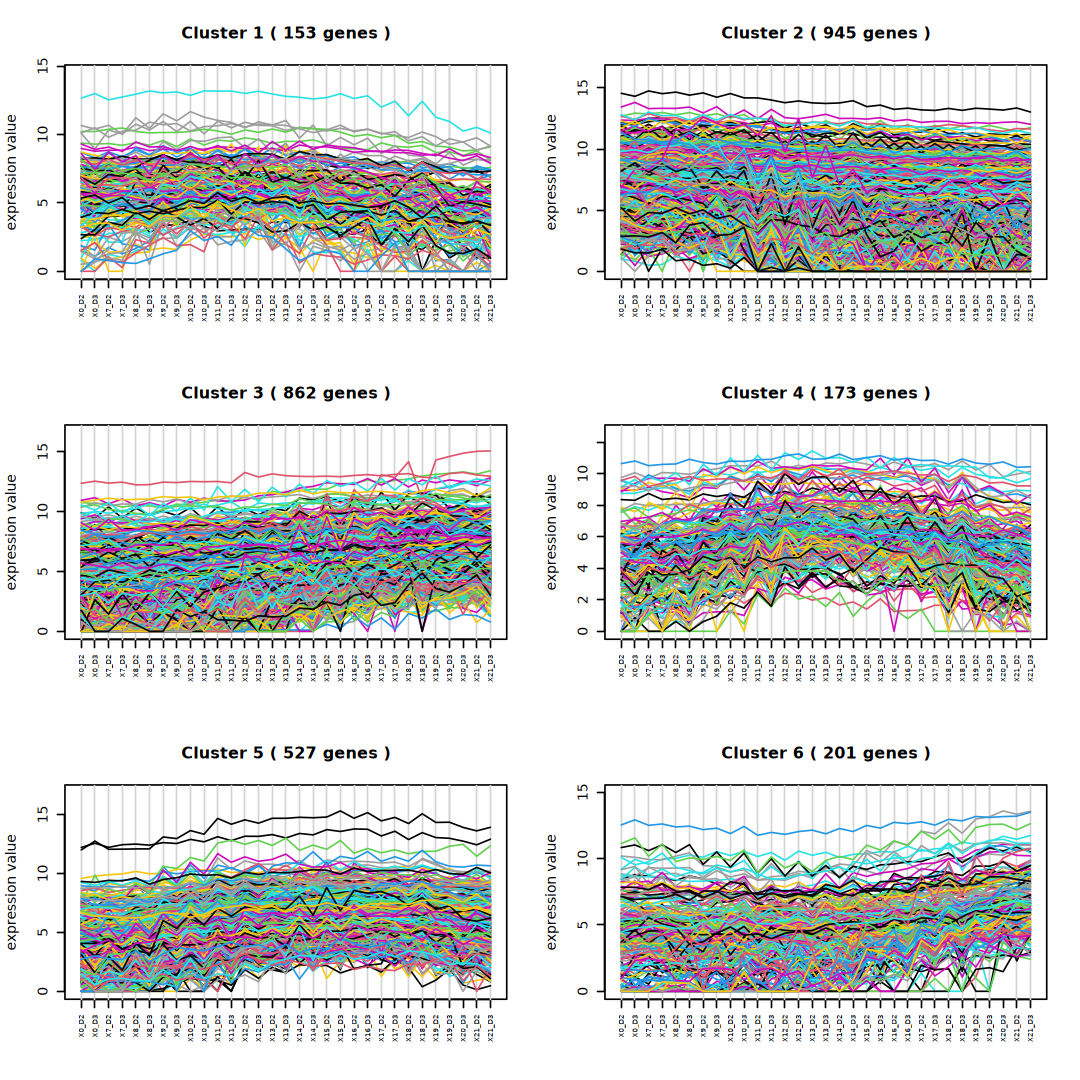

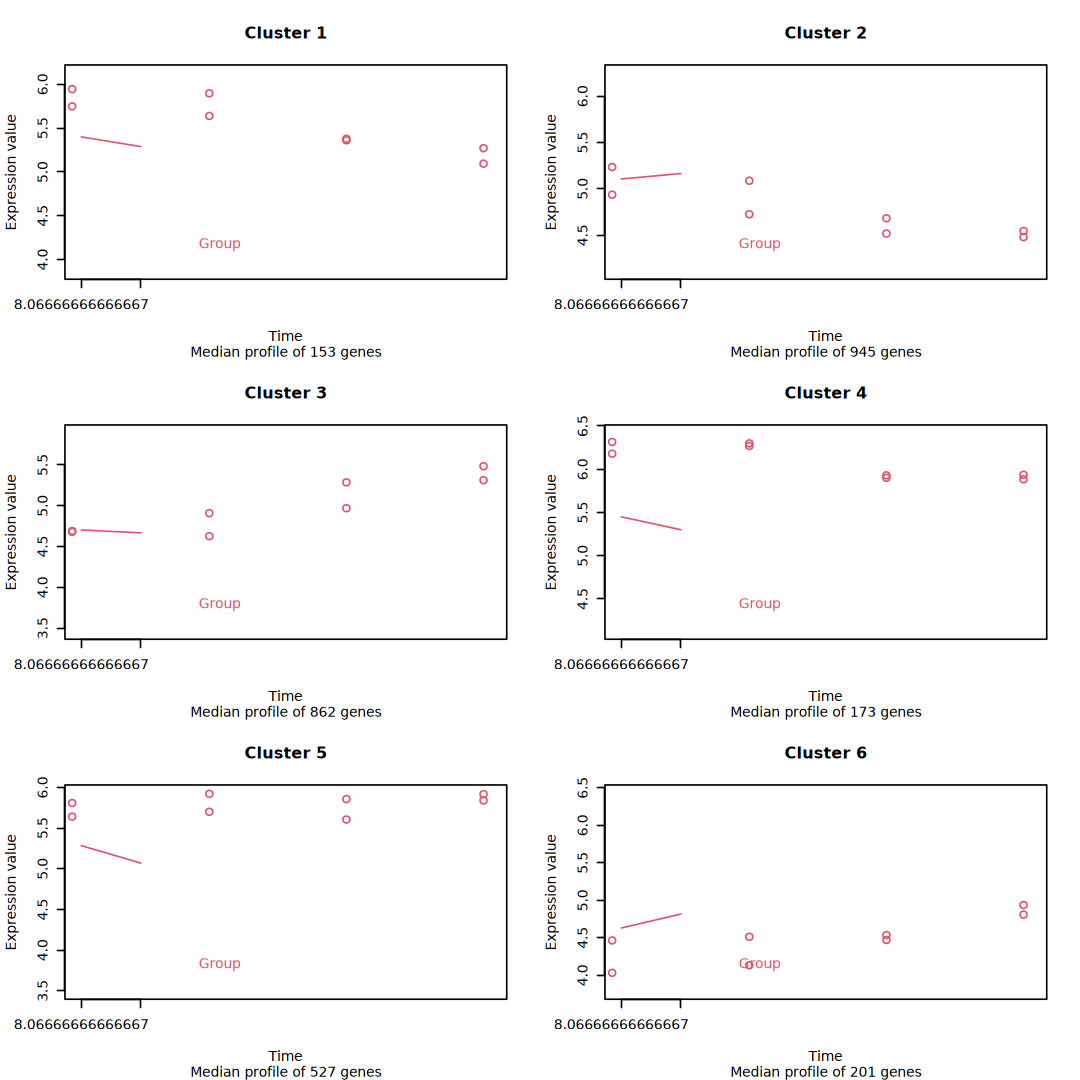

In [74]:
options(repr.plot.width = 9, repr.plot.height = 9)
cl_masigpro <- see.genes(sigs$sig.genes, k = 6)

In [75]:
cl_masigpro$cut |> table()


  1   2   3   4   5   6 
153 945 862 173 527 201 

## 4). WGCNA

## 5). Impulse Model

### ImpulseDE2?
- David S Fischer, Fabian J Theis, Nir Yosef, Impulse model-based differential expression analysis of time course sequencing data, Nucleic Acids Research, Volume 46, Issue 20, 16 November 2018, Page e119, https://doi.org/10.1093/nar/gky675.

In [76]:
# library(ImpulseDE2)
# # inputData: data.frame(sample, time, condition), raw counts矩阵
# res <- runImpulseDE2(matCount = counts, dfAnnotation = meta,
#                     boolCaseCtrl = FALSE, scaNProc = 4)
# head(res$vecDEGene)

## Clustering Evaluation

### Adjusted Rand Index, ARI

In [77]:
suppressPackageStartupMessages(library(mclust))

In [78]:
gene_lists <- list(
    names(cl_mfuzz$cluster),
    names(cl_tcseq@cluster),
    names(cl_masigpro$cut))

common_genes <- Reduce(intersect, gene_lists)

vector_mfuzz    <- cl_mfuzz$cluster[common_genes]
vector_tcseq    <- cl_tcseq@cluster[common_genes]
vector_masigpro <- cl_masigpro$cut[common_genes]

In [79]:
ari_mfuzz_tcseq    <- adjustedRandIndex(vector_mfuzz, vector_tcseq)
ari_mfuzz_masigpro <- adjustedRandIndex(vector_mfuzz, vector_masigpro)
ari_tcseq_masigpro <- adjustedRandIndex(vector_tcseq, vector_masigpro)

cat("ARI (Mfuzz vs tcseq):", ari_mfuzz_tcseq, "\n")
cat("ARI (Mfuzz vs maSigPro):", ari_mfuzz_masigpro, "\n")
cat("ARI (tcseq vs maSigPro):", ari_tcseq_masigpro, "\n")

ARI (Mfuzz vs tcseq): 0.6094344 
ARI (Mfuzz vs maSigPro): 0.6165721 
ARI (tcseq vs maSigPro): 0.4693308 


### Jaccard Similarity

In [80]:
table_match <- table(vector_mfuzz, vector_tcseq)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("TCseq_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_tcseq == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

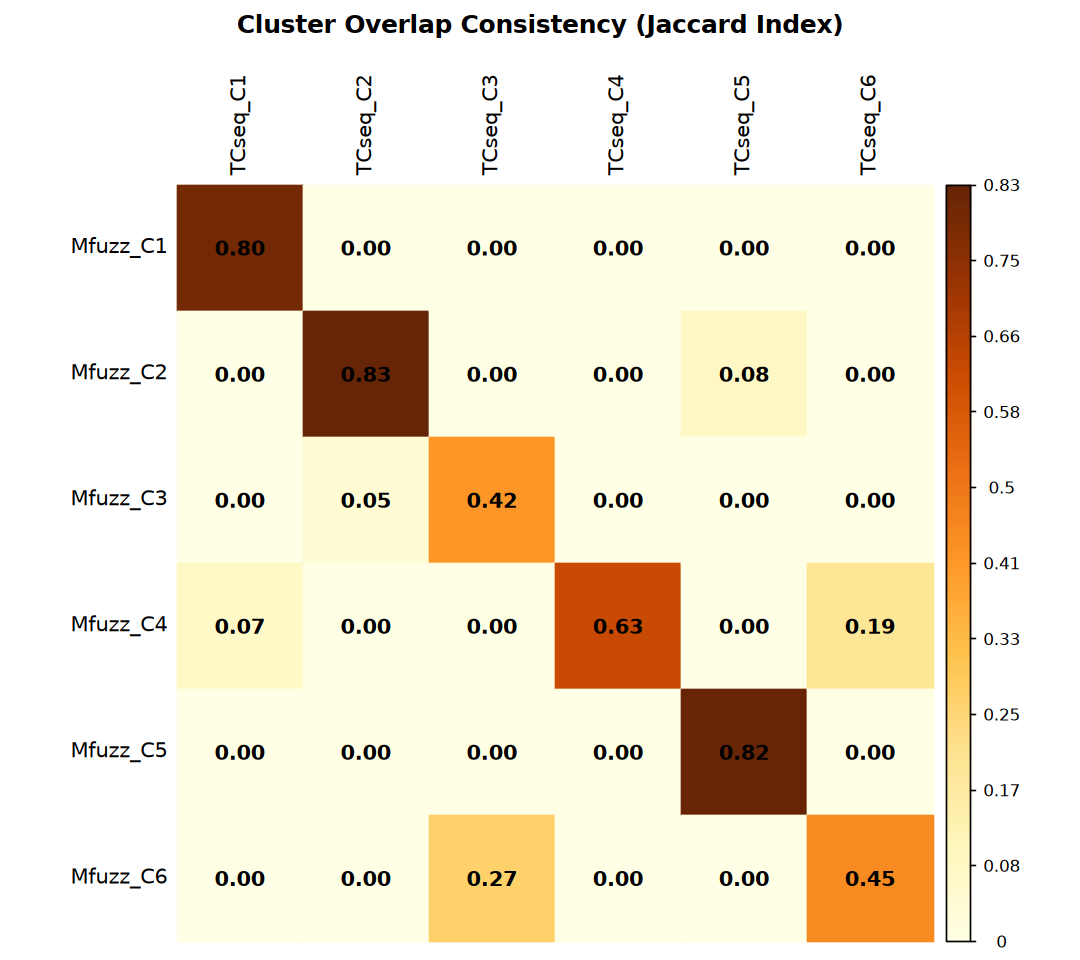

In [81]:
options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

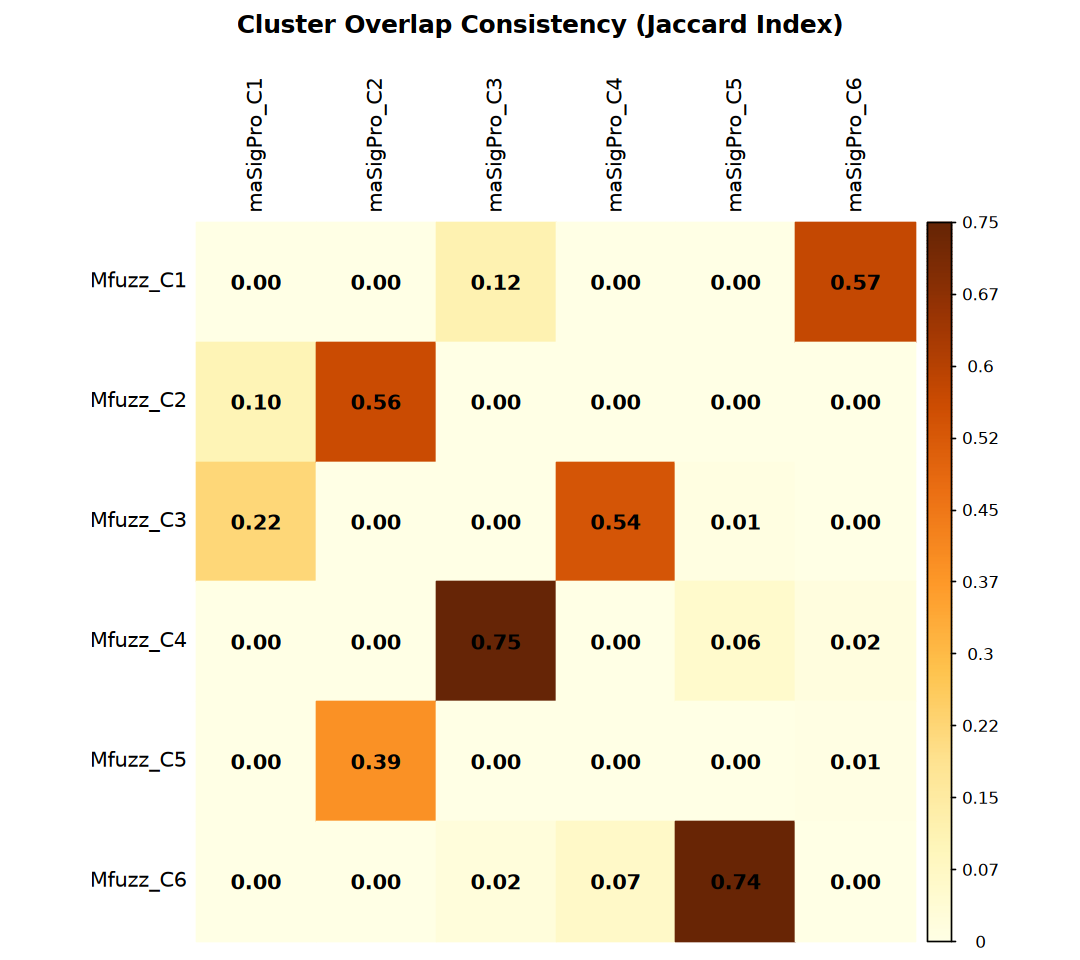

In [82]:
table_match <- table(vector_mfuzz, vector_masigpro)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("maSigPro_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_masigpro == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

## Clustering Visualization

### Lineplot

In [83]:
norm_mat <- log2(tpm + 1)

In [84]:
norm_expr_df <- norm_mat |> as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "value")

In [85]:
plot_lineplot <- function(cluster, expression, coldata, group, method) {
    data.frame(cluster = cluster) |>
        rownames_to_column(var = "gene_id") |>
        mutate(cluster = factor(paste0("cluster", cluster))) |>
        add_count(cluster, name = "count") |>
        left_join(expression, by = "gene_id") |>
        left_join(coldata, by = "sample") |>
        group_by(across(all_of(group)), Replicate, cluster, count) |>
        summarize(
            median_value = median(value, na.rm = TRUE), 
            .groups = "drop") |>
        mutate(
            cluster_label = paste0(cluster, " (n=", count, ")"),
            cluster_label = factor(cluster_label)) |>
        ungroup() |>
    ggplot(aes(x = .data[[group]], y = median_value)) +
        # geom_point(position = position_jitter(width = 0.1), alpha = 0.7) + 
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun = mean, geom = "line", linewidth = 1, alpha = 0.8) +
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        scale_x_discrete(expand = expansion(mult = c(0.1, 0.1))) +
        scale_y_continuous(expand = expansion(mult = c(0.1, 0.1))) +
        scale_color_brewer(palette = "Set3") +
        labs(
            title = paste0("Time-course: ", method), 
            color = "Cluster", x = NULL, y = "Median Expression") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16))
}

In [86]:
coldata <- colData(eSet) |> as.data.frame() |> 
    rownames_to_column(var = "sample")

p1 <- plot_lineplot(
    cluster = cl_mfuzz$cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Time", method = "Mfuzz")
p2 <- plot_lineplot(
    cluster = cl_tcseq@cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Time", method = "TCseq")
p3 <- plot_lineplot(
    cluster = cl_masigpro$cut, expression = norm_expr_df, 
    coldata = coldata, group = "Time", method = "maSigPro")

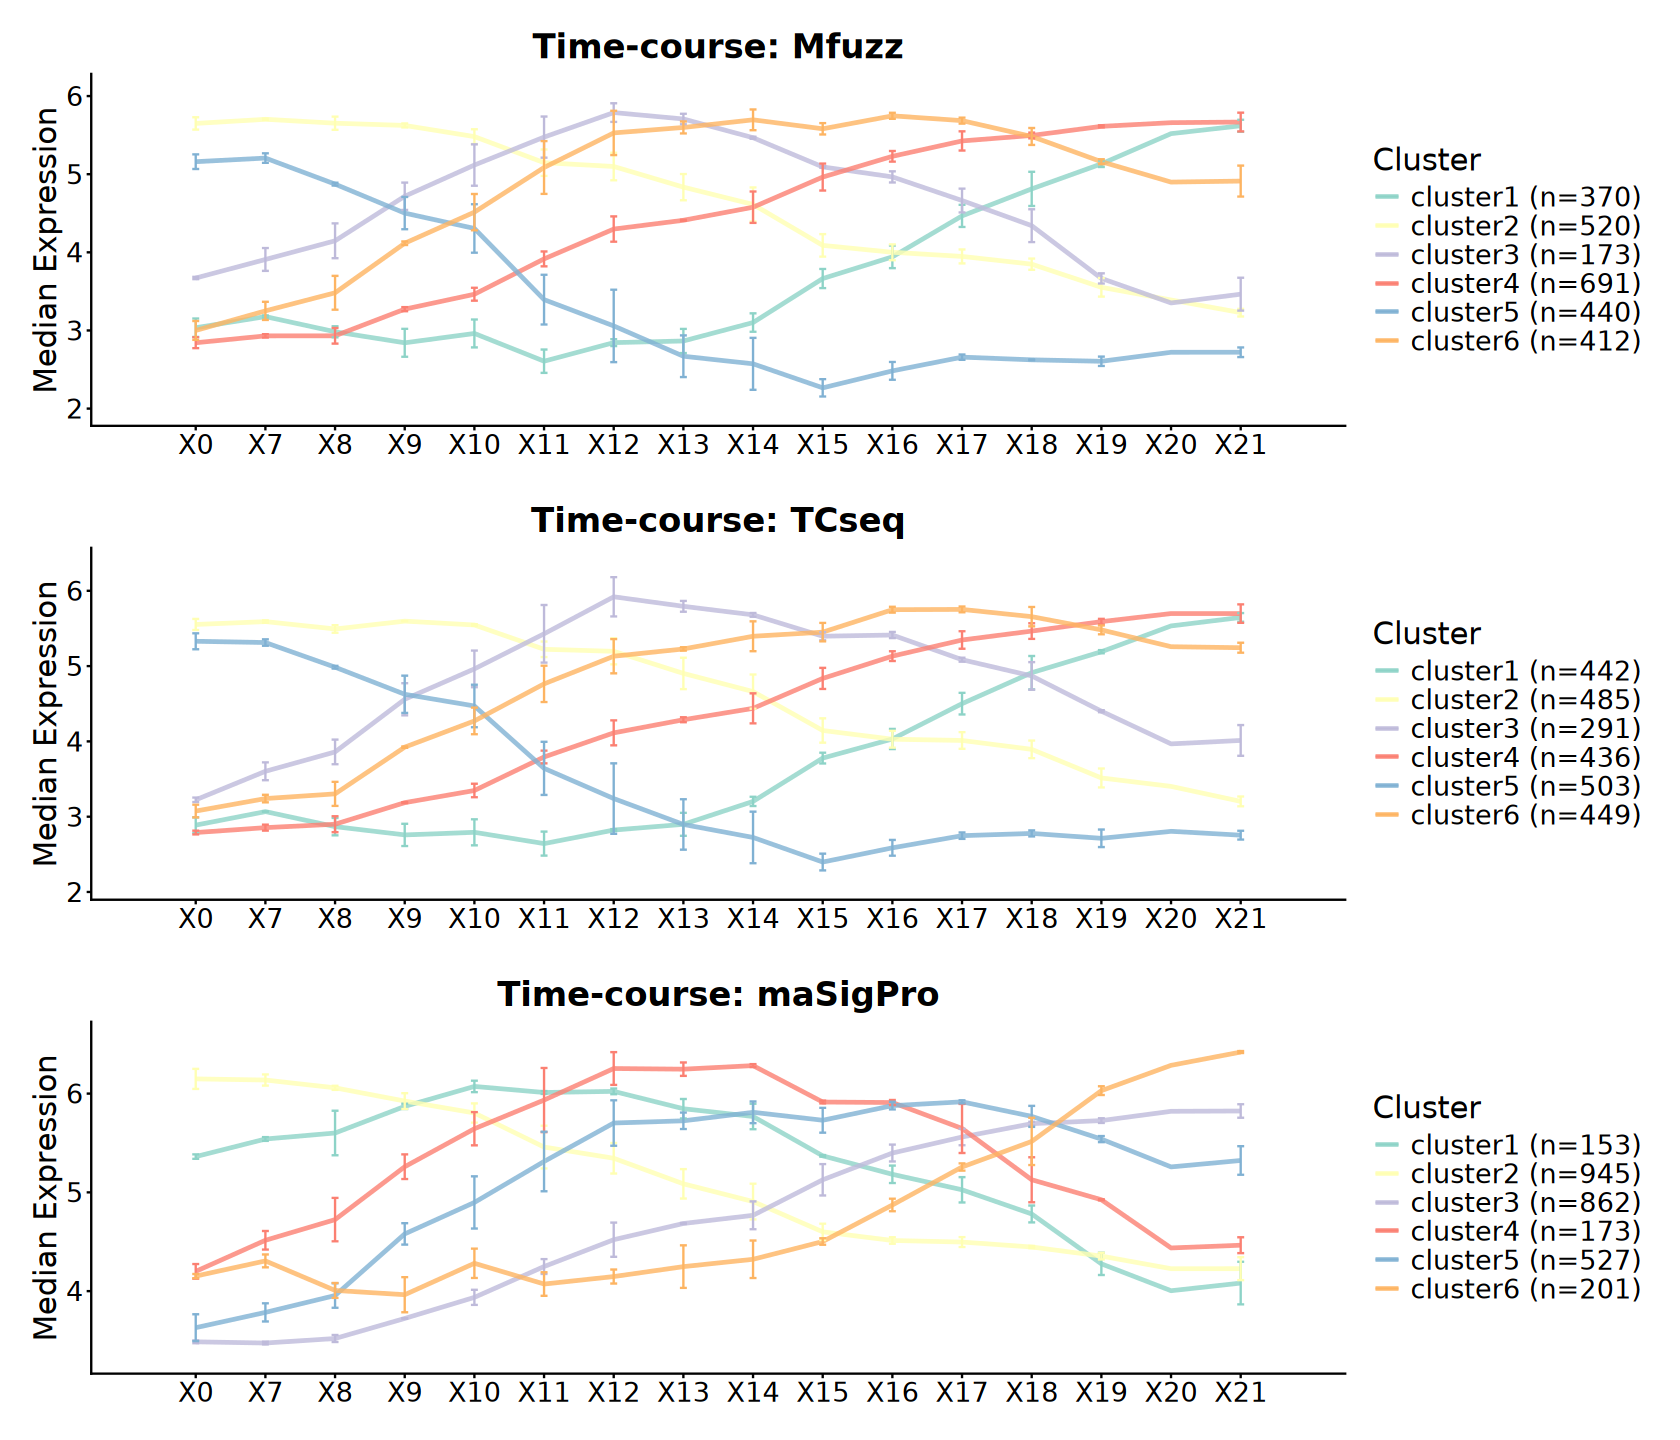

In [87]:
options(repr.plot.width = 14, repr.plot.height = 12)
p1 / p2 / p3

### Heatmap

In [88]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Time)

In [89]:
ar <- cl_mfuzz$cluster |> data.frame(Cluster = _) |>
    mutate(Cluster = factor(paste0("cluster", Cluster))) |>
    arrange(Cluster)

In [90]:
heatmap_dat <- norm_mat[rownames(ar), ]

In [91]:
group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(nlevels(dds$Time)),
    levels(dds$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

anno_colors <- list(
    Time = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

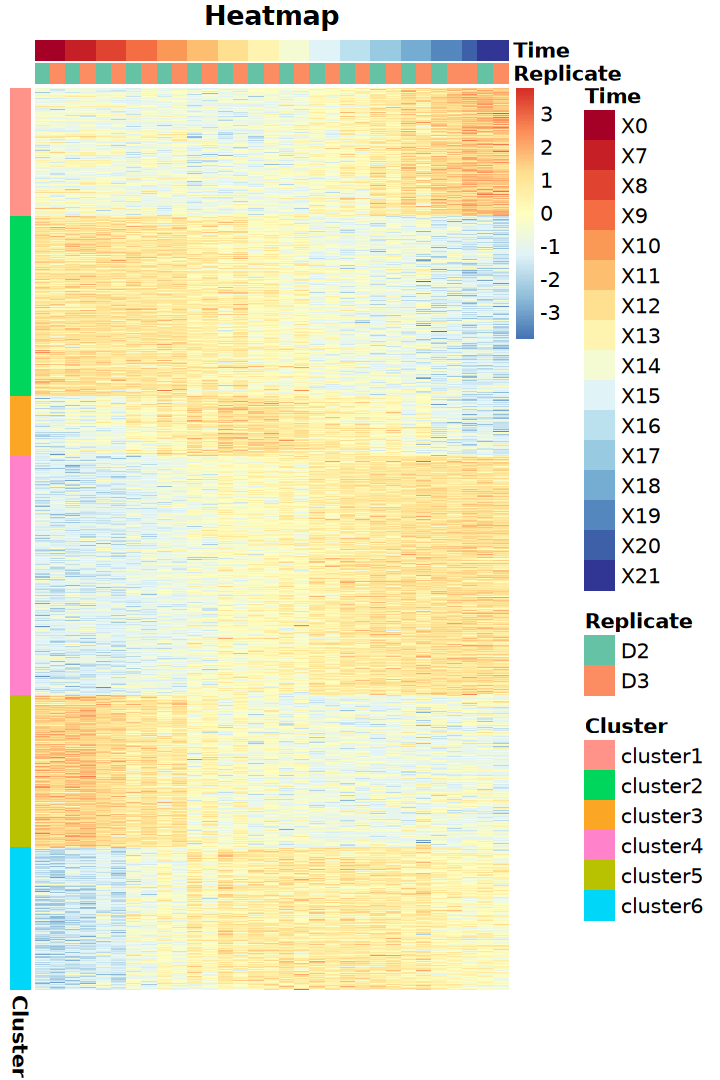

In [92]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row", 
    cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_row = ar, annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

# 7. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [93]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [94]:
gene_map <- bitr(
    rowData(dds)$symbol, OrgDb = org.Hs.eg.db, fromType = "SYMBOL", 
    toType = c("ENTREZID"), drop = FALSE)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(rowData(dds)$symbol, OrgDb = org.Hs.eg.db, fromType = "SYMBOL", :
“3.11% of input gene IDs are fail to map...”


In [95]:
membership_df <- cl_mfuzz$membership |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

In [96]:
cluster_df <- cl_mfuzz$cluster |> 
    data.frame(cluster = _) |>
    mutate(cluster = as.character(cluster)) |>
    rownames_to_column(var = "gene_id") |>
    left_join(membership_df, by = c("gene_id", "cluster")) |>
    filter(membership > 0.6) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
        dplyr::select(symbol, type) |>
        rownames_to_column("gene_id"), 
        by = "gene_id") |>
    left_join(gene_map, by = c("symbol" = "SYMBOL"))

table(cluster_df$cluster)
head(cluster_df)


  1   2   3   4   5   6 
355 494 170 667 409 393 

,gene_id,cluster,membership,symbol,type,ENTREZID
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,ENSG00000001617,2,0.9920499,SEMA3F,protein_coding,6405
2,ENSG00000002933,4,0.9998236,TMEM176A,protein_coding,55365
3,ENSG00000003096,2,0.9928723,KLHL13,protein_coding,90293
4,ENSG00000003137,6,0.8491390,CYP26B1,protein_coding,56603
5,ENSG00000003147,2,0.9956494,ICA1,protein_coding,3382
6,ENSG00000003249,2,0.9999255,DBNDD1,protein_coding,79007


In [97]:
# membership_df <- cl_tcseq@membership |> 
#     as.data.frame() |> 
#     rownames_to_column(var = "gene_id") |> 
#     pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

# cluster_df <- cl_tcseq@cluster |> 
#     data.frame(cluster = _) |>
#     mutate(cluster = as.character(cluster)) |>
#     rownames_to_column(var = "gene_id") |>
#     left_join(membership_df, by = c("gene_id", "cluster")) |>
#     filter(membership > 0.6) |>
#     left_join(
#         rowData(dds) |> as.data.frame() |> 
#         dplyr::select(symbol, type) |>
#         rownames_to_column("gene_id"), 
#         by = "gene_id") |>
#     left_join(gene_map, by = c("gene_id" = "ENSEMBL"))

# table(cluster_df$cluster)

In [98]:
gene_list <- split(cluster_df$symbol, cluster_df$cluster)

In [99]:
ego_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichGO,
    universe = rowData(dds)$symbol, 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [100]:
ego_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,BP,GO:0030198,extracellular matrix organization,33/320,232/11481,0.1422414,5.103354,10.691051,8.143071e-15,9.236957e-12,8.054497e-12,33
2,1,BP,GO:0043062,extracellular structure organization,33/320,232/11481,0.1422414,5.103354,10.691051,8.143071e-15,9.236957e-12,8.054497e-12,33
3,1,BP,GO:0045229,external encapsulating structure organization,33/320,232/11481,0.1422414,5.103354,10.691051,8.143071e-15,9.236957e-12,8.054497e-12,33
4,1,BP,GO:0030199,collagen fibril organization,13/320,63/11481,0.2063492,7.403423,8.629424,1.435306e-08,1.221086e-05,1.064770e-05,13
5,1,BP,GO:0085029,extracellular matrix assembly,10/320,36/11481,0.2777778,9.966146,9.123123,3.284597e-08,2.235496e-05,1.949322e-05,10
6,1,BP,GO:0048514,blood vessel morphogenesis,35/320,491/11481,0.0712831,2.557504,5.972627,3.007829e-07,1.705940e-04,1.487556e-04,35


In [101]:
gene_list <- split(cluster_df$ENTREZID, cluster_df$cluster)

In [102]:
ekegg_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichKEGG, 
    universe = unique(gene_map$ENTREZID), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [103]:
ekegg_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,Environmental Information Processing,Signaling molecules and interaction,hsa04080,Neuroactive ligand-receptor interaction,15/175,114/5644,0.1315789,4.243609,6.258042,1.848187e-06,5.045549e-04,4.727467e-04,15
2,1,Environmental Information Processing,Signaling molecules and interaction,hsa04082,Neuroactive ligand signaling,11/175,84/5644,0.1309524,4.223401,5.323984,4.827714e-05,6.589830e-03,6.174393e-03,11
3,2,Genetic Information Processing,Translation,hsa03010,Ribosome,22/222,154/5644,0.1428571,3.631918,6.700362,1.068980e-07,2.993144e-05,2.970639e-05,22
4,2,Human Diseases,Infectious disease: viral,hsa05171,Coronavirus disease,20/222,159/5644,0.1257862,3.197915,5.688174,3.273216e-06,4.582502e-04,4.548047e-04,20
5,4,Environmental Information Processing,Signaling molecules and interaction,hsa04512,ECM-receptor interaction,20/338,59/5644,0.3389831,5.660415,9.081734,6.613598e-11,1.917943e-08,1.649919e-08,20
6,4,Environmental Information Processing,Signaling molecules and interaction,hsa04518,Integrin signaling,27/338,116/5644,0.2327586,3.886656,7.928111,4.990789e-10,7.236644e-08,6.225352e-08,27


### Clustered Heatmap

In [104]:
norm_mat <- log2(tpm + 1)

#### 1). Heatmap-ggplot2

In [105]:
plot_df <- norm_mat |> t() |> scale() |> t() |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "expression") |>
    right_join(cluster_df, by = "gene_id") |>
    mutate(
        sample = factor(sample, levels = colnames(dds)), 
        cluster = as.factor(cluster)) |>
    arrange(cluster, membership, sample, expression)

head(plot_df)

gene_id,sample,expression,cluster,membership,symbol,type,ENTREZID
<chr>,<fct>,<dbl>,<fct>,<dbl>,<chr>,<chr>,<chr>
ENSG00000223749,X0_D2,-1.1156961,1,0.6008705,MIR503HG,lncRNA,84848
ENSG00000223749,X0_D3,-1.3375854,1,0.6008705,MIR503HG,lncRNA,84848
ENSG00000223749,X7_D2,-1.6606697,1,0.6008705,MIR503HG,lncRNA,84848
ENSG00000223749,X7_D3,-1.1969193,1,0.6008705,MIR503HG,lncRNA,84848
ENSG00000223749,X8_D2,-1.1798919,1,0.6008705,MIR503HG,lncRNA,84848
ENSG00000223749,X8_D3,-0.8059745,1,0.6008705,MIR503HG,lncRNA,84848


In [106]:
line_plot <- ggplot(plot_df, aes(x = sample, y = expression)) +
    geom_path(
        aes(group = gene_id, color = membership),
        linewidth = 0.5, alpha = 0.5) +
    scale_color_distiller(
        palette = "RdYlBu", limits = c(0, 1), 
        breaks = seq(0, 1, 0.5)) +
    scale_y_continuous(breaks = c(-2, 0, 2)) + 
    facet_wrap(
        ~ cluster, ncol = 1, strip.position = "left",
        labeller = "label_both") + 
    coord_cartesian(clip = "off") + 
    theme_classic() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_text(size = 16),
        strip.background = element_rect(fill = brewer.pal(6, "Set3"), colour = NA),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

In [107]:
heatmap_plot <- ggplot(plot_df, aes(x = sample, y = gene_id)) +
    geom_tile(aes(fill = expression)) +
    scale_fill_distiller(palette = "RdYlBu", breaks = c(-2, 0, 2)) +
    facet_wrap(~ cluster, ncol = 1, scales = "free_y") + 
    theme_void() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_blank(),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank())

In [108]:
strip_plot <- colData(dds) |> as.data.frame() |> 
    rownames_to_column("sample") |>
    mutate(sample = factor(sample, levels = colnames(dds))) |>
    ggplot(aes(x = sample, y = 1)) +
        geom_tile(aes(color = Time, fill = Time), width = 1, height = 1) +
        scale_x_discrete(expand = c(0, 0)) +
        scale_color_manual(
            values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
            na.value = "grey50") +
        scale_fill_manual(
            values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
            na.value = "grey50") +
        theme_void() +
        theme(
            legend.title = element_text(size = 18, vjust = 1),
            legend.text = element_text(size = 16))

In [109]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    left_join(
        plot_df |> group_by(cluster) |> 
            summarise(y_pos = mean(as.numeric(factor(gene_id)))), 
        by = c("Cluster" = "cluster"))

In [110]:
annotation_plot <- ggplot(go_annotations, aes(x = 0, y = y_pos)) +
    geom_text(
        aes(color = GO_term, label = GO_term), 
        hjust = 0, size = 4, show.legend = FALSE) +
    facet_wrap(~ Cluster, ncol = 1, scales = "free_y") +
    scale_color_brewer(palette = "Dark2") + 
    xlim(c(0, 1)) +
    theme_test() + 
    theme(
        strip.text = element_blank(),
        axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank())

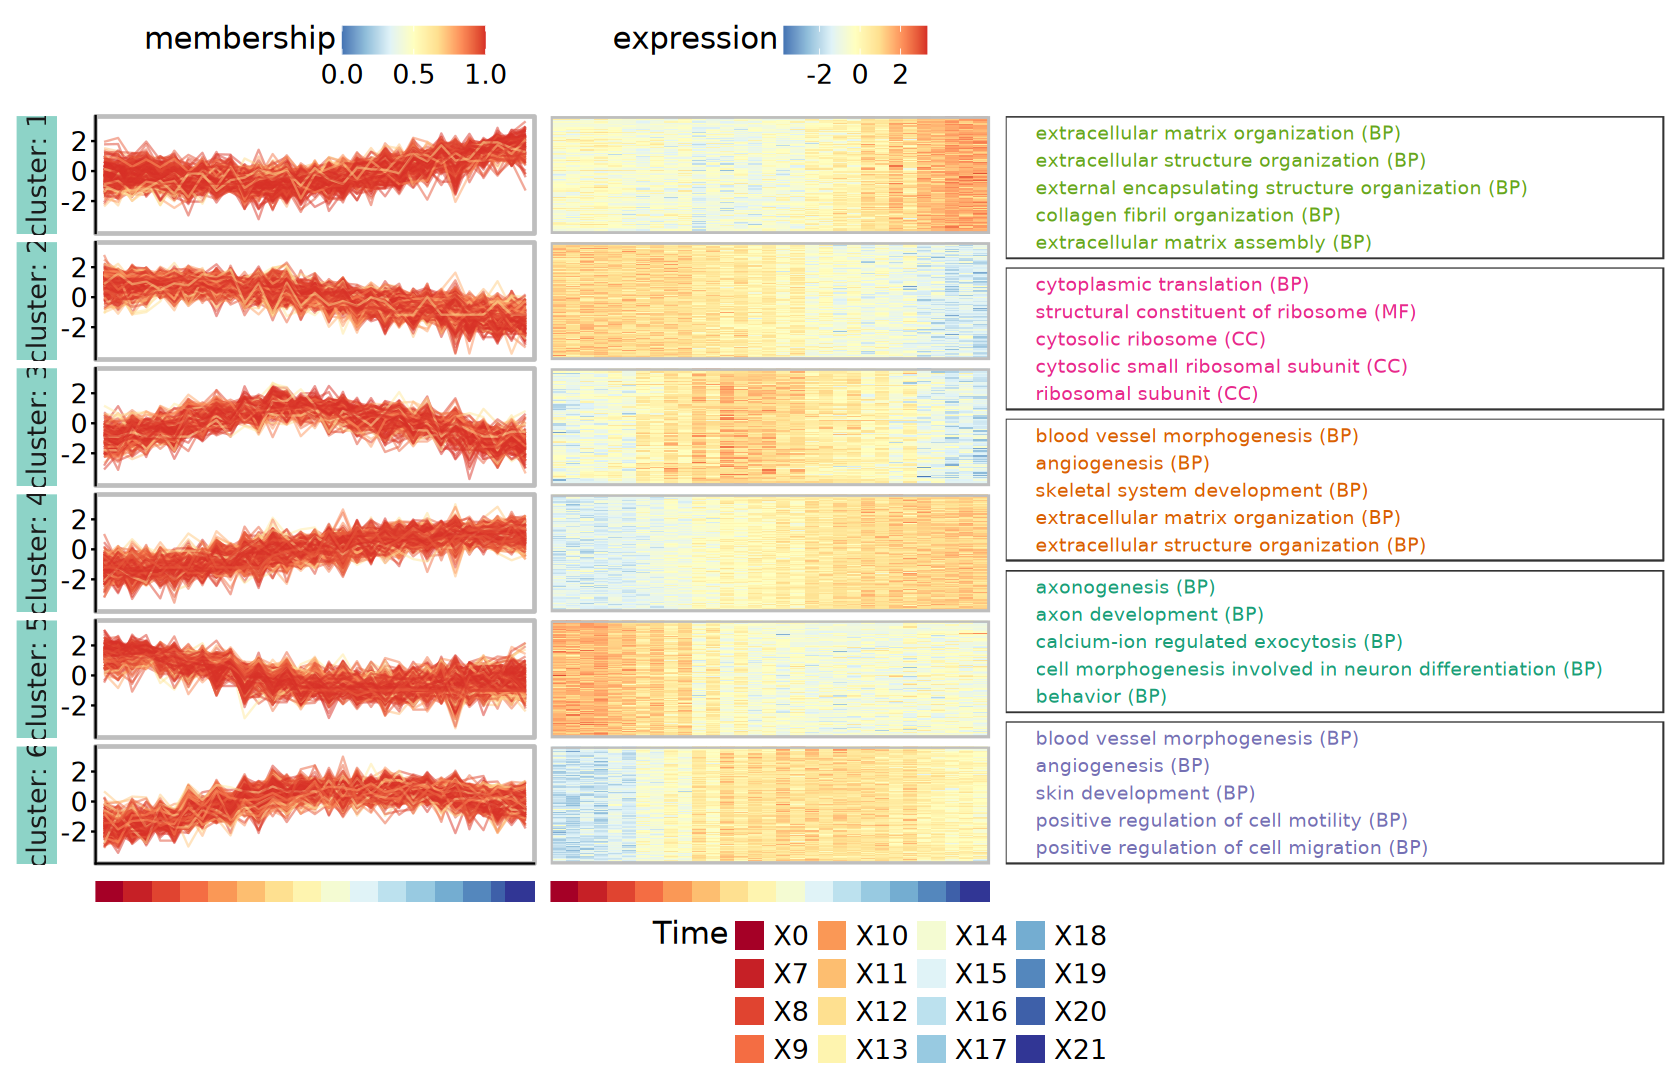

In [111]:
options(repr.plot.width = 14, repr.plot.height = 9)
top_row <- line_plot + heatmap_plot + annotation_plot +
    plot_layout(widths = c(2, 2, 3))
bottom_row <- strip_plot + strip_plot + plot_spacer() +
    plot_layout(widths = c(2, 2, 3), guides = "collect") & 
    theme(legend.position = "bottom")

top_row / bottom_row + 
    plot_layout(heights = c(1, 0.03)) &
    theme(
        plot.margin = margin(5, 5, 5, 5),
        strip.placement = "outside")

#### 2). ComplexHeatmap

In [112]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [113]:
cluster_df <- cluster_df |>
    mutate(cluster = factor(paste0("cluster", cluster)))

In [114]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Time, Replicate)

group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(nlevels(dds$Time)),
    levels(dds$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Time = group_colors, 
        Replicate = replicate_colors))

In [115]:
ar <- cluster_df |> 
    dplyr::select(gene_id, Cluster = cluster) |>
    column_to_rownames("gene_id") |>
    arrange(Cluster)

cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

left_anno <- rowAnnotation(
    df = ar, col = list(Cluster = cluster_colors),
    show_legend = FALSE)

In [116]:
heatmap_dat <- norm_mat[rownames(ar), ]

heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

In [117]:
gene_labels <- cluster_df |>
    filter(type == "protein_coding") |>
    group_by(cluster) |>
    slice_max(order_by = membership, n = 5, with_ties = FALSE) |>
    ungroup()

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$symbol[
    match(rownames(heatmap_dat)[mark_rows], 
    gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)),
    width = unit(2.5, "cm"))

In [118]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Time", labels = levels(dds$Time))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_cluster <- Legend(
    labels = levels(ar$Cluster), title = "Cluster", 
    legend_gp = gpar(fill = cluster_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [119]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    mutate(Cluster = factor(paste0("cluster", Cluster)))

In [120]:
go_term_data_list <- split(go_annotations$GO_term, go_annotations$Cluster)

In [121]:
right_annotation <- rowAnnotation(
    textbox = anno_textbox(
        ar$Cluster, go_term_data_list,
        background_gp = gpar(fill = "#ffffff"),
        gp = gpar(fontsize = 12), max_width = unit(10, "cm"), 
        add_new_line = TRUE, round_corners = TRUE), 
    width = unit(12, "cm"))
# word_wrap = TRUE, 

In [122]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

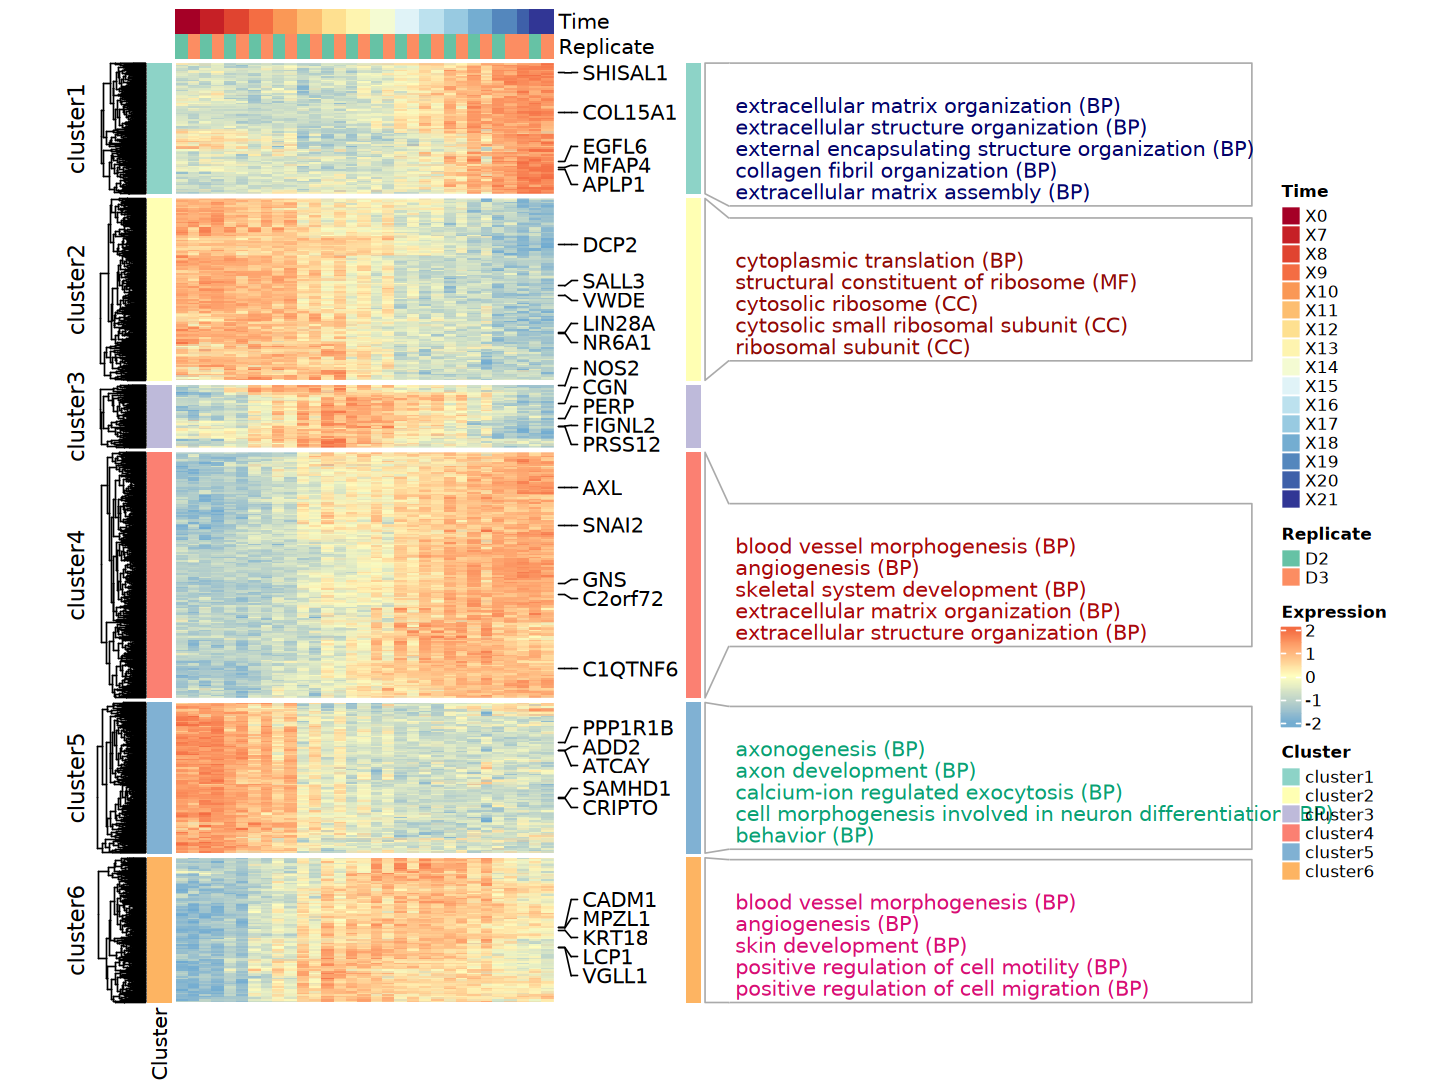

In [123]:
options(repr.plot.width = 12, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [124]:
s_heatmap_dat <- heatmap_dat |> t() |> scale() |> t()

In [125]:
panel_fun_boxplot <- function(s_heatmap_dat, group_colors = NULL) {
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        fills <- if (is.null(group_colors)) "grey70" else group_colors |>
            rep(each = 3)
        bw <- min(0.1, 0.9 / max(1, ncol(tmp)))

        grid::pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid::grid.rect()                         
        for (i in seq_len(ncol(norm))) {
            grid.boxplot(
                norm[, i], pos = pos[i],
                direction = "vertical",
                box_width = bw, outline = FALSE,
                gp = grid::gpar(col = "grey50", fill = fills[i]))
        }
        grid::grid.lines(
            x = pos, y = apply(norm, 2, median, na.rm = TRUE),
            gp = grid::gpar(col = "red", lwd = 0.5))
        grid::grid.text(
            paste0("Genes: ", nrow(tmp)), 0.5, 0.9, 
            gp = grid::gpar(fontsize = 6))
        grid::popViewport()
    }
}

In [126]:
panel_fun <- panel_fun_boxplot(s_heatmap_dat, group_colors)
left_anno2 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [127]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno2, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

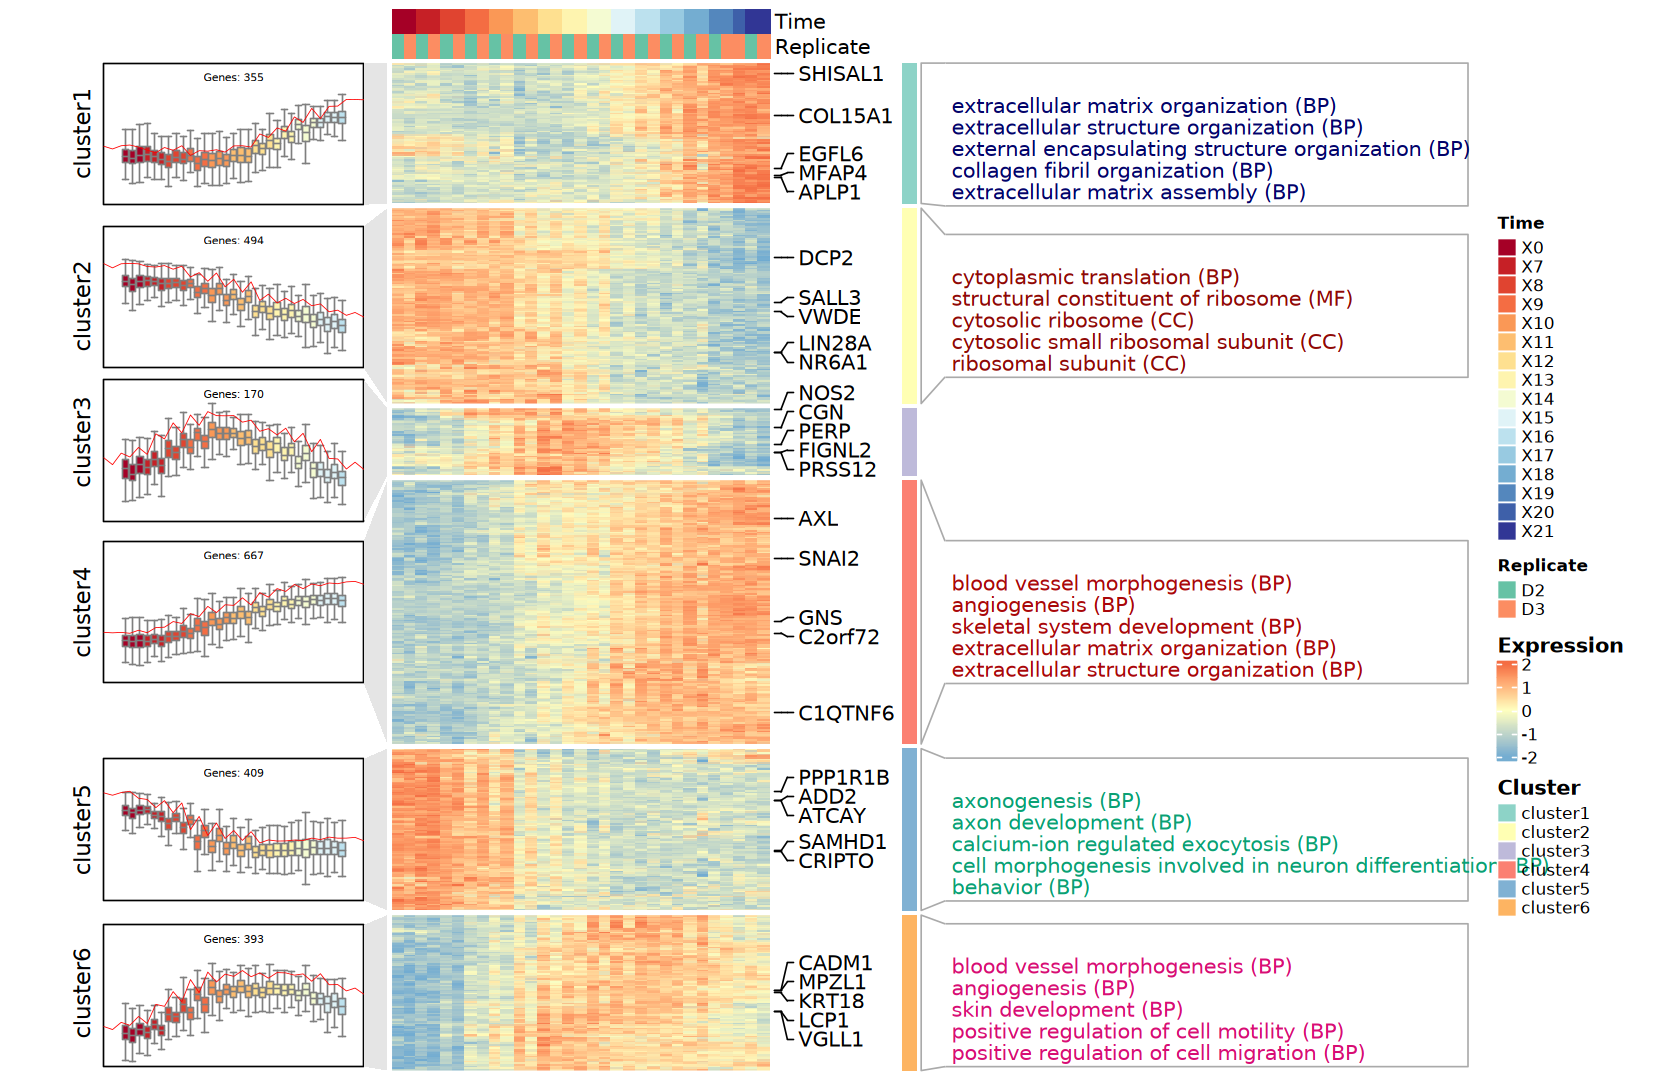

In [128]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [129]:
panel_fun_pathplot <- function(
    s_heatmap_dat, cluster_df, palette = c("blue","white","red")) {
    
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        # pos <- scales::rescale(1:ncol(tmp), to = c(0, 1))
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        
        mem <- cluster_df$membership[match(rownames(tmp), cluster_df$gene_id)]
        mem_idx <- round(mem * 100)
        line_colors <- grDevices::colorRampPalette(palette)(100)
        line_cols <- line_colors[mem_idx]

        pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid.rect()
        for (i in seq_len(nrow(norm))) {
            grid.lines(
                x = pos, y = norm[i, ], 
                gp = gpar(col = line_cols[i], lwd = 0.5))
        }
        grid.text(paste0("Genes: ", nrow(tmp)), 0.5, 0.9, gp = grid::gpar(fontsize = 6))
        popViewport()
    }
}

In [130]:
palette = c(
    "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
    "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
    "#F46D43", "#D53E4F", "#9E0142")

In [131]:
panel_fun <- panel_fun_pathplot(s_heatmap_dat, cluster_df, palette)
left_anno3 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [132]:
line_colors <- circlize::colorRamp2(
    breaks = seq(0, 1, length.out = length(palette)), 
    colors = palette)

lg_line <- Legend(
    title = "Membership", col_fun = line_colors, 
    at = c(0, 0.5, 1), labels = c("0", "0.5", "1"))

In [133]:
combined_leg <- list(lg_heatmap, lg_group, lg_replicate, lg_line) |>
    packLegend(direction = "vertical")

In [134]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno3, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

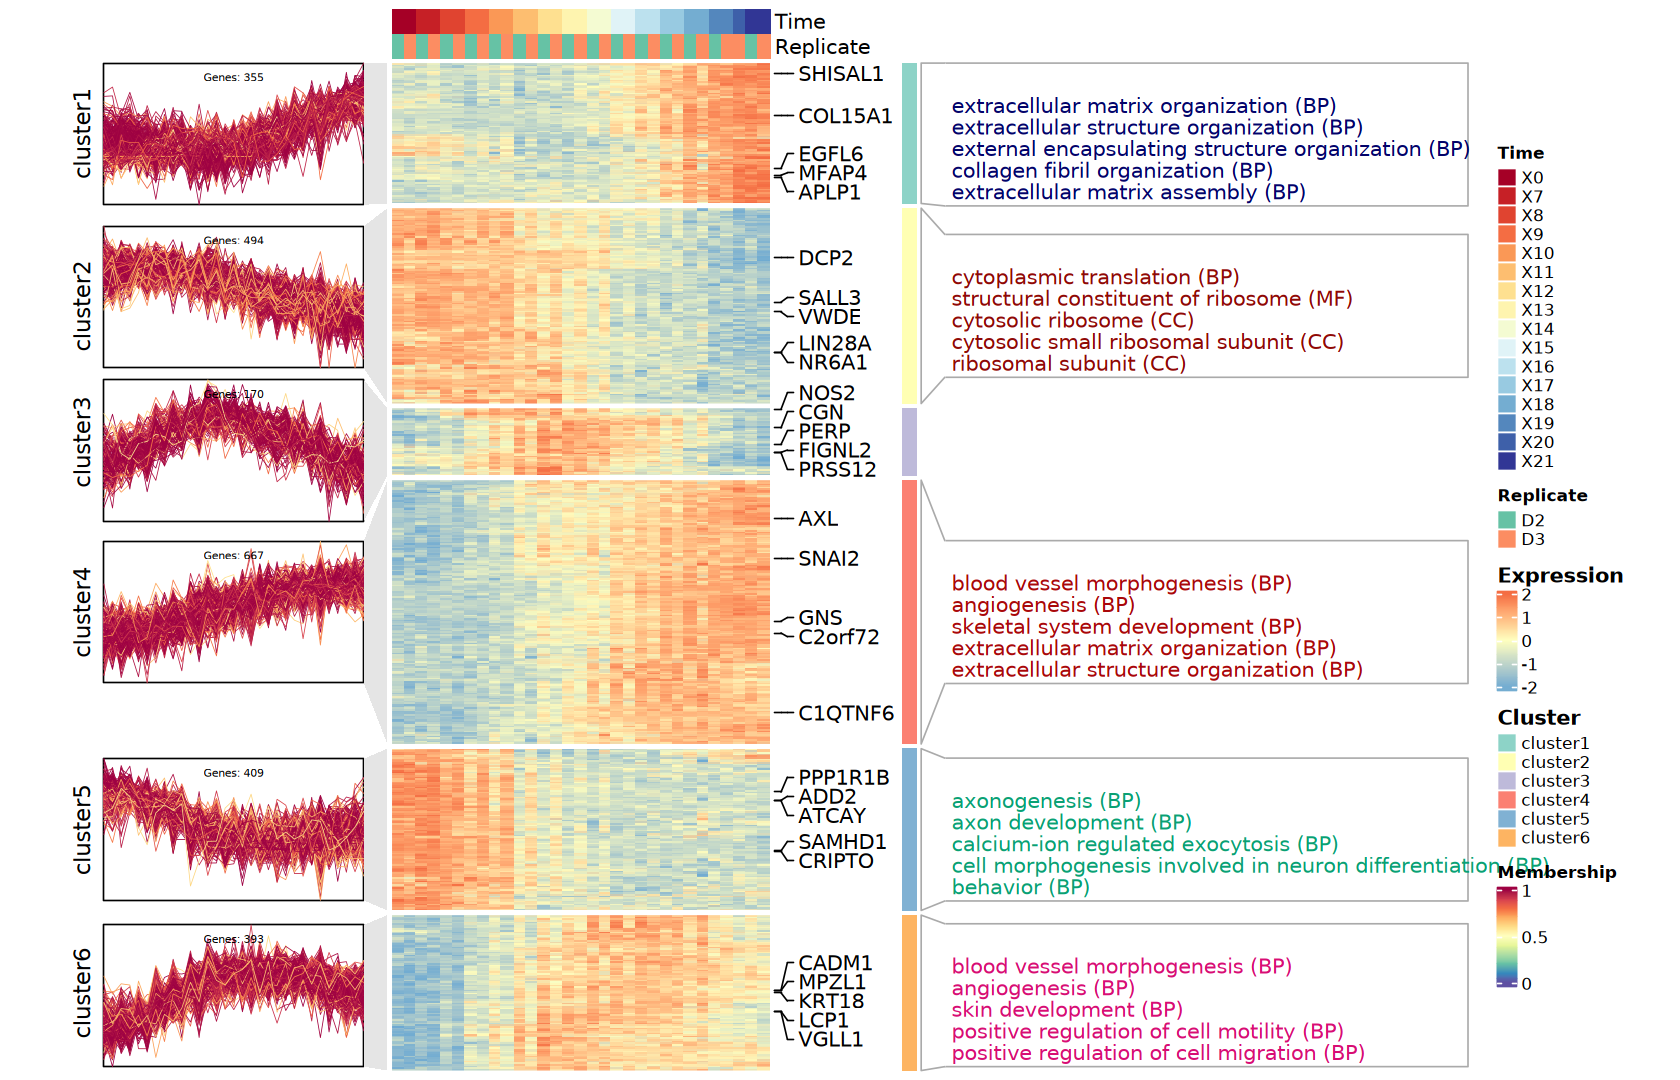

In [135]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_line),
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

#### 3). [ClusterGVis](https://github.com/junjunlab/ClusterGVis)

> - To enhance clustering and visualization of time-series gene expression data from RNA-Seq experiments.

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)